# Elliptic Bitcoin Transaction Fraud Detection -- End-to-End Pipeline

Consolidated pipeline reproducing the project's best-performing submission (`final_submission.csv`, public leaderboard **0.95876**), end to end in one notebook. Sections:

0. **Setup and data loading**
1. **Exploratory data analysis** -- target imbalance, temporal split, feature redundancy and drift, and the transaction graph.
2. **Baseline models** -- tabular features only (XGBoost, LightGBM, logistic regression, random forest) under temporal cross-validation and a locked holdout.

Then the modelling pipeline:

3. **Graph feature engineering** -- structural degree, a causal/leak-free self-risk score (`risk_prob_self`), and neighbor-risk aggregates, all computed walk-forward so no row ever sees a label from its own evaluation future.
4. **Feature pruning** -- correlation redundancy (`|r|>0.9`), Cohen's d, and XGBoost importance combine to cut 174 features (165 raw tabular + 9 graph) down to 82, validated with both a holdout comparison and a 14-period horizon curve (not a single lucky/unlucky split).
5. **Hyperparameter tuning** -- Optuna (TPE sampler) searches XGBoost's hyperparameters on temporal (non-shuffled) cross-validation folds within periods 1-21.
6-7. **Evaluation and XGBoost submission** -- the tuned model retrained on all labeled periods (1-35), scoring the real, unlabeled test set (36-49) with one frozen model (public **0.95730**).
8-10. **Blends** -- `graph_structure_v2` + XGBoost (0.95706), and XGBoost + an MLP with quantile scaling and periodic embeddings, rank-blended 3:1 (0.95830).
11. **Final submission** -- the same blend with the MLP trained on time-decay weights (0.98), compared against every decay, within-period-rank and graph-smoothing variant tried (**0.95876**).

Across this project, almost every attempt to improve on the XGBoost model -- other tree models (LightGBM, HistGradientBoosting, CatBoost), stacking with weaker models, ~15 hand-engineered structural features, multi-seed bagging, pseudo-labeling, rank rescaling, and repeated hyperparameter re-searches -- scored at or below it. The one thing that helped was blending in a strong model that ranks transactions differently: the MLP in the last section.

## 0. Setup and data loading

In [243]:
import os
import random
import time
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import (
    roc_auc_score, f1_score, precision_score, recall_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
from catboost import CatBoostClassifier

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)
RANDOM_STATE = 42

DEVICE = torch.device("cpu")
# xgboost and torch each ship an OpenMP runtime; a single torch thread avoids a known deadlock between them (mainly on macOS)
torch.set_num_threads(1)

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
edges = pd.read_csv("data/txs_edgelist.csv")
sample_submission = pd.read_csv("data/sample_submission.csv")

feature_cols = [c for c in train.columns if c.startswith("feat_")]

labeled = train[train["label"].notna()].copy()
labeled["label"] = labeled["label"].astype(int)

# Every node (train + test) the graph features need to cover, in one table.
all_tx = pd.concat(
    [
        train[["txId", "time_step"] + feature_cols],
        test[["txId", "time_step"] + feature_cols],
    ],
    ignore_index=True,
)

print("Tabular feature count:", len(feature_cols))
print("Labeled rows:", len(labeled))
print("All nodes (train + test):", len(all_tx))

Tabular feature count: 165
Labeled rows: 31235
All nodes (train + test): 157101


## 1. Exploratory data analysis

From `01_eda.ipynb`. The data is the Elliptic Bitcoin transaction graph: each row is a transaction with 165 anonymised
features, a `time_step` (1-49), and a label (illicit / licit / unknown). Transactions are linked by payment-flow edges.
The analysis below covers the target and its imbalance, missing values, the time structure, feature redundancy and drift,
and the transaction graph. Variables created here are prefixed `eda_` wherever a later section reuses the name.

In [244]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Edges shape:", edges.shape)

display(train.head())
display(test.head())
display(edges.head())

Train shape: (141772, 168)
Test shape: (15329, 168)
Edges shape: (234355, 2)


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,feat_10,feat_11,feat_12,feat_13,feat_14,feat_15,feat_16,feat_17,feat_18,feat_19,feat_20,feat_21,feat_22,feat_23,feat_24,feat_25,feat_26,feat_27,feat_28,feat_29,feat_30,feat_31,feat_32,feat_33,feat_34,feat_35,feat_36,feat_37,feat_38,feat_39,feat_40,feat_41,feat_42,feat_43,feat_44,feat_45,feat_46,feat_47,feat_48,feat_49,feat_50,feat_51,feat_52,feat_53,feat_54,feat_55,feat_56,feat_57,feat_58,feat_59,feat_60,feat_61,feat_62,feat_63,feat_64,feat_65,feat_66,feat_67,feat_68,feat_69,feat_70,feat_71,feat_72,feat_73,feat_74,feat_75,feat_76,feat_77,feat_78,feat_79,feat_80,feat_81,feat_82,feat_83,feat_84,feat_85,feat_86,feat_87,feat_88,feat_89,feat_90,feat_91,feat_92,feat_93,feat_94,feat_95,feat_96,feat_97,feat_98,feat_99,feat_100,feat_101,feat_102,feat_103,feat_104,feat_105,feat_106,feat_107,feat_108,feat_109,feat_110,feat_111,feat_112,feat_113,feat_114,feat_115,feat_116,feat_117,feat_118,feat_119,feat_120,feat_121,feat_122,feat_123,feat_124,feat_125,feat_126,feat_127,feat_128,feat_129,feat_130,feat_131,feat_132,feat_133,feat_134,feat_135,feat_136,feat_137,feat_138,feat_139,feat_140,feat_141,feat_142,feat_143,feat_144,feat_145,feat_146,feat_147,feat_148,feat_149,feat_150,feat_151,feat_152,feat_153,feat_154,feat_155,feat_156,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,label
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,-0.167933,-0.049707,-0.164402,-0.028741,-0.035391,-0.042955,-0.013282,-0.057195,-0.169609,-0.171154,-0.174473,-1.373657,-1.371460,-0.139731,-0.148912,-0.080147,-0.155661,-0.010763,-0.012107,-0.139733,-0.148907,-0.080147,-0.155661,-0.010669,-0.012005,-0.024669,-0.031272,-0.023045,-0.026215,0.001428,0.001483,-0.227215,-0.239368,-0.075256,-0.234952,0.037468,0.043444,-0.227203,-0.243236,-0.097895,-0.235896,0.036577,0.042345,-0.414005,-0.488340,-0.232553,-0.467554,0.048767,0.052956,-0.039149,-0.172895,-0.163126,-0.160932,-1.316342,-1.315388,-0.039144,-0.172884,-0.163115,-0.160925,-1.316333,-1.315375,-0.017032,-0.030026,-0.017640,-0.015071,-0.140763,-0.140335,-0.095403,-0.264376,-0.250523,-0.263703,1.133527,1.135947,-0.059013,-0.262368,-0.255111,-0.259194,1.125590,1.128038,-0.293773,-0.159732,0.034039,-0.183816,1.135523,1.135279,-0.169160,-0.201584,-0.116817,-0.191472,-0.014659,-0.018849,-1.457953,-1.494057,-0.083459,-1.485972,-0.088798,-0.090437,-0.166550,-0.216536,-0.134546,-0.194817,-0.003175,-0.004094,-1.096336,-1.267340,-0.349933,-1.230441,-0.004358,-0.004194,-0.116425,-0.176617,-0.137323,-0.152464,-0.026060,-0.027660,-0.093145,-0.143707,-0.097719,-0.127462,0.003143,0.002426,-0.120950,-0.199145,-0.187993,-0.212948,1.064205,1.063787,-1.373782,-1.354735,-0.297975,-1.403698,1.342003,1.340733,-0.171601,-0.458162,-0.423588,-0.440883,-1.015963,-1.016230,-0.968903,-0.375715,0.759748,-0.768329,1.488113,1.487932,-0.216814,-0.605631,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,NaN
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,-0.167948,-0.049707,-0.164417,-0.028741,-0.035391,-0.042955,-0.013282,-0.055327,-0.169757,-0.171477,-0.174490,0.887058,0.884557,-0.139731,-0.148912,-0.080147,-0.155661,-0.010763,-0.012107,-0.139733,-0.148907,-0.080147,-0.155661,-0.010669,-0.012005,-0.024669,-0.031272,-0.023045,-0.026215,0.001428,0.001483,-0.227215,-0.239368,-0.075256,-0.234952,0.037468,0.043444,-0.227203,-0.243236,-0.097895,-0.235896,0.036577,0.042345,-0.413965,-0.488307,-0.232553,-0.467516,0.048767,0.052956,-0.039151,-0.172895,-0.163126,-0.160933,0.923473,0.923011,-0.039146,-0.172884,-0.163114,-0.160926,0.923516,0.923110,-0.017032,-0.030026,-0.017640,-0.015071,-0.140763,-0.140335,-0.095403,-0.264425,-0.250574,-0.263753,-0.169119,-0.167165,-0.059013,-0.262424,-0.255168,-0.259251,-0.187191,-0.185274,-0.293692,-0.760700,-0.692777,-0.719789,-1.084907,-1.084845,-0.170113,-0.202332,-0.116817,-0

,index,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,feat_10,feat_11,feat_12,feat_13,feat_14,feat_15,feat_16,feat_17,feat_18,feat_19,feat_20,feat_21,feat_22,feat_23,feat_24,feat_25,feat_26,feat_27,feat_28,feat_29,feat_30,feat_31,feat_32,feat_33,feat_34,feat_35,feat_36,feat_37,feat_38,feat_39,feat_40,feat_41,feat_42,feat_43,feat_44,feat_45,feat_46,feat_47,feat_48,feat_49,feat_50,feat_51,feat_52,feat_53,feat_54,feat_55,feat_56,feat_57,feat_58,feat_59,feat_60,feat_61,feat_62,feat_63,feat_64,feat_65,feat_66,feat_67,feat_68,feat_69,feat_70,feat_71,feat_72,feat_73,feat_74,feat_75,feat_76,feat_77,feat_78,feat_79,feat_80,feat_81,feat_82,feat_83,feat_84,feat_85,feat_86,feat_87,feat_88,feat_89,feat_90,feat_91,feat_92,feat_93,feat_94,feat_95,feat_96,feat_97,feat_98,feat_99,feat_100,feat_101,feat_102,feat_103,feat_104,feat_105,feat_106,feat_107,feat_108,feat_109,feat_110,feat_111,feat_112,feat_113,feat_114,feat_115,feat_116,feat_117,feat_118,feat_119,feat_120,feat_121,feat_122,feat_123,feat_124,feat_125,feat_126,feat_127,feat_128,feat_129,feat_130,feat_131,feat_132,feat_133,feat_134,feat_135,feat_136,feat_137,feat_138,feat_139,feat_140,feat_141,feat_142,feat_143,feat_144,feat_145,feat_146,feat_147,feat_148,feat_149,feat_150,feat_151,feat_152,feat_153,feat_154,feat_155,feat_156,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165
0,0,200459281,36,-0.172879,-0.058452,0.463609,-0.121970,-0.043875,-0.113002,-0.061584,-0.163536,-0.169352,-0.049707,-0.165839,-0.028741,-0.035391,-0.042955,-0.013282,-0.057065,-0.171067,-0.172840,-0.176141,0.887058,0.884557,-0.132105,-0.144045,-0.080147,-0.149199,-0.010763,-0.012107,-0.132105,-0.144040,-0.080147,-0.149198,-0.010669,-0.012005,-0.024669,-0.031272,-0.023045,-0.026215,0.001428,0.001483,-0.211084,-0.224180,-0.075256,-0.219162,0.037468,0.043444,-0.211222,-0.227604,-0.097895,-0.220010,0.036577,0.042345,1.041317,0.722046,-0.232553,0.928888,0.048767,0.052956,-0.039151,-0.172895,-0.163126,-0.160933,0.923473,0.923011,-0.039146,-0.172884,-0.163115,-0.160926,0.923516,0.923110,-0.017032,-0.030026,-0.01764,-0.015071,-0.140763,-0.140335,-0.095403,-0.264425,-0.250574,-0.263753,-0.169119,-0.167165,-0.059013,-0.262424,-0.255168,-0.259251,-0.187191,-0.185274,-0.293853,-0.761944,-0.694210,-0.720952,1.135523,1.135279,-0.170634,-0.202741,-0.116817,-0.192915,-0.014659,-0.018849,0.801938,0.803958,-0.083459,0.805795,-0.088798,-0.090437,-0.088200,-0.156977,-0.134546,-0.119971,-0.003175,-0.004094,1.023860,0.787435,-0.349933,0.939106,-0.004358,-0.004194,-0.116425,-0.176617,-0.137323,-0.152464,-0.026060,-0.027660,-0.093145,-0.143707,-0.097719,-0.127462,0.003143,0.002426,-0.124290,-0.193567,-0.180149,-0.207226,1.064205,1.063787,0.739947,0.502358,-0.301617,0.663148,1.342003,1.340733,0.398289,4.421702,5.327376,4.467085,1.301966,1.301281,0.117111,0.669709,0.759748,0.445895,1.488113,1.487932,0.090912,1.794379,2.262621,1.947206,1.461330,1.461369,-0.098889,-0.087490,-0.084674,-0.140597,-1.760926,-1.760984
1,1,199944769,36,-0.172828,0.339970,1.018602,0.178180,-0.043875,0.222447,-0.061584,-0.163620,-0.169419,-0.049636,-0.165915,-0.684027,-0.280462,-0.042955,-0.013282,-0.057112,-0.171012,-0.172773,-0.176081,0.887058,0.884557,-0.139732,-0.148899,-0.080135,-0.155656,-1.256340,-1.350850,-0.139734,-0.148895,-0.080135,-0.155656,-1.256230,-1.350662,-0.024669,-0.031272,-0.023045,-0.026215,0.001428,0.001483,-0.227215,-0.229204,-0.054534,-0.232386,-2.497500,-2.278049,-0.227203,-0.234577,-0.071096,-0.233661,-2.454328,-2.289334,-0.414017,1.293405,2.274018,0.412020,-2.195071,-2.314499,-0.039151,-0.172895,-0.163125,-0.160932,0.923473,0.923011,-0.039146,-0.172884,-0.163114,-0.160925,0.923516,0.923110,-0.017032,-0.030026,-0.01764,-0.015071,-0.140763,-0.140335,-0.095403,-0.264229,-0.250372,-0.263555,1.133527,1.135947,-0.059013,-0.262340,-0.255082,-0.259166,1.125590,1.128038,-0.293836,0.012863,0.242795,-0.029899,1.135523,1.135279,-0.171000,-0.196295,-0.105635,-0.191358,-1.851472,-1.589295,0.801

,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206


**Summary:** Loaded 141,772 train rows and 15,329 test rows, both with 168 columns (165 anonymized `feat_*` columns plus `txId`/`time_step`; train also has `label`, test also has an extra `index` column). The edge list has 234,355 transaction-to-transaction edges.

Train and test share the same id/feature columns; train's only extra column is `label` (the target), and test's only extra
column is `index`, a row id used by the submission file.

### 1.1 Identifiers and the target

In [245]:
# check for duplicates and overlap in txId
print("Train unique txId:", train["txId"].nunique())
print("Train rows:", len(train))

print("Test unique txId:", test["txId"].nunique())
print("Test rows:", len(test))

print("\nDuplicate txId in train:", train["txId"].duplicated().sum())
print("Duplicate txId in test:", test["txId"].duplicated().sum())

print(
    "Train/test txId overlap:",
    len(set(train["txId"]) & set(test["txId"]))
)

Train unique txId: 141772
Train rows: 141772
Test unique txId: 15329
Test rows: 15329

Duplicate txId in train: 0
Duplicate txId in test: 0
Train/test txId overlap: 0


**Summary:** No duplicate `txId` values in either train or test, and zero `txId` overlap between them — train and test are a clean, disjoint split.

In [246]:
print(train["label"].value_counts(dropna=False))

print("\nPercentages:")
print(
    train["label"]
    .value_counts(dropna=False, normalize=True)
    .mul(100)
    .round(2)
)

label
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64

Percentages:
label
NaN    77.97
0.0    19.46
1.0     2.57
Name: proportion, dtype: float64


**Summary:** 77.97% of train rows are unlabeled, 19.46% are licit (0), and only 2.57% are illicit (1). Most of the training data has no label and can't be used directly for supervised learning.

In [247]:
# labeled (from the setup cell) holds the 31,235 rows with a known label; the rest are unknown
unlabeled = train[train["label"].isna()]

print("Total train:", len(train))
print("Labeled:", len(labeled))
print("Unlabeled:", len(unlabeled))

Total train: 141772
Labeled: 31235
Unlabeled: 110537


**Summary:** 31,235 of 141,772 train rows have a known label; the remaining 110,537 are held out as `unlabeled` (potentially useful later for semi-supervised approaches, e.g. pseudo-labeling or graph propagation).

In [248]:
# class imbalance among labeled data
class_counts = labeled["label"].value_counts().sort_index()

print(class_counts)

n_licit = (labeled["label"] == 0).sum()
n_illicit = (labeled["label"] == 1).sum()

print("\nLicit:", n_licit)
print("Illicit:", n_illicit)
print("Illicit proportion:", n_illicit / len(labeled))
print("Licit : Illicit ratio:", n_licit / n_illicit)

label
0    27591
1     3644
Name: count, dtype: int64

Licit: 27591
Illicit: 3644
Illicit proportion: 0.1166639987193853
Licit : Illicit ratio: 7.571624588364434


**Summary:** Among labeled rows: 27,591 licit vs 3,644 illicit — an 11.7% illicit rate and roughly a 7.6:1 licit:illicit ratio. Significant class imbalance — plan to use class weights, resampling, or a metric like PR-AUC/F1 rather than accuracy.

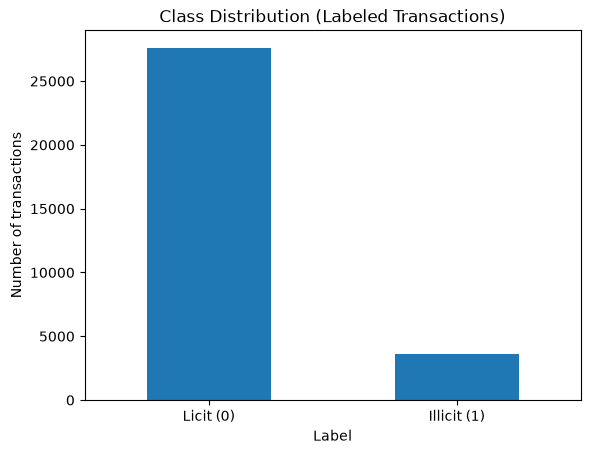

In [249]:
class_counts.plot(kind="bar")

plt.title("Class Distribution (Labeled Transactions)")
plt.xlabel("Label")
plt.ylabel("Number of transactions")
plt.xticks([0, 1], ["Licit (0)", "Illicit (1)"], rotation=0)
plt.show()

**Summary:** Bar chart visualizes the imbalance above — the illicit bar is roughly 1/8 the height of the licit bar.

### 1.2 Missing values

In [250]:
missing = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_pct": train.isna().mean() * 100
})

missing = missing.sort_values("missing_pct", ascending=False)

display(missing.head(30))

,missing_count,missing_pct
label,110537,77.968146
feat_114,0,0.000000
feat_106,0,0.000000
feat_107,0,0.000000
feat_108,0,0.000000
feat_109,0,0.000000
feat_110,0,0.000000
feat_111,0,0.000000
feat_112,0,0.000000
feat_113,0,0.000000


**Summary:** Only `label` has missing values (77.97% missing, i.e. the unlabeled rows). Every `feat_*` and metadata column is fully populated (0% missing) — no imputation needed for features.

In [251]:
missing_comparison = pd.DataFrame({
    "train_missing_pct": train[feature_cols].isna().mean() * 100,
    "test_missing_pct": test[feature_cols].isna().mean() * 100
})

display(
    missing_comparison
    .sort_values("train_missing_pct", ascending=False)
    .head(20)
)

,train_missing_pct,test_missing_pct
feat_1,0.0,0.0
feat_105,0.0,0.0
feat_107,0.0,0.0
feat_108,0.0,0.0
feat_109,0.0,0.0
feat_110,0.0,0.0
feat_111,0.0,0.0
feat_112,0.0,0.0
feat_113,0.0,0.0
feat_114,0.0,0.0


**Summary:** Train and test features are both fully populated (0% missing) with identical coverage — no train/test missingness mismatch to worry about.

### 1.3 Time structure

In [252]:
print("Train time range:")
print(train["time_step"].min(), "->", train["time_step"].max())

print("\nTest time range:")
print(test["time_step"].min(), "->", test["time_step"].max())

print("\nTrain time steps:")
print(sorted(train["time_step"].unique()))

print("\nTest time steps:")
print(sorted(test["time_step"].unique()))

Train time range:
1 -> 35

Test time range:
36 -> 49

Train time steps:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35)]

Test time steps:
[np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49)]


**Summary:** Train spans `time_step` 1–35 and test spans 36–49 with zero overlap — this is a **temporal (forward-in-time) split**, not a random split. Validation should mimic this (e.g. time-based/forward-chaining CV) rather than random k-fold, or you'll leak future information into training.

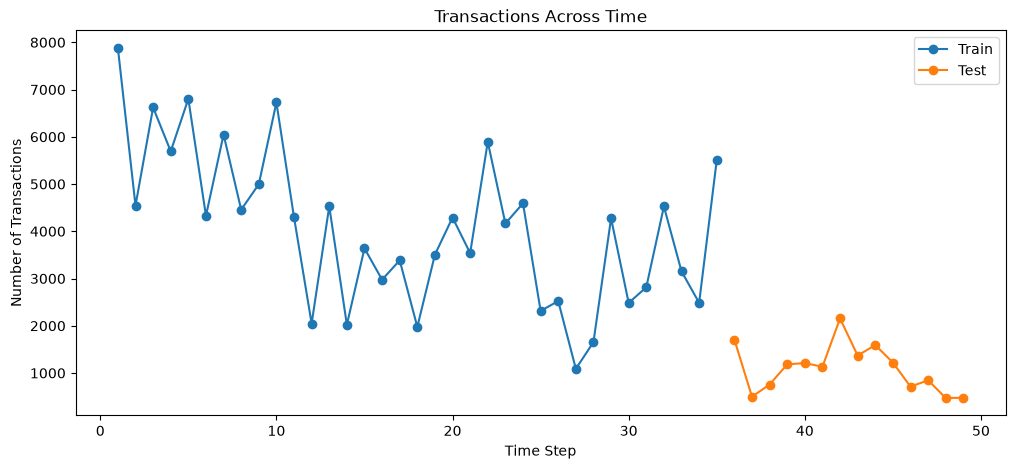

In [253]:
# plot transactions across time steps
train_time_counts = train.groupby("time_step").size()
test_time_counts = test.groupby("time_step").size()

plt.figure(figsize=(12, 5))

plt.plot(
    train_time_counts.index,
    train_time_counts.values,
    marker="o",
    label="Train"
)

plt.plot(
    test_time_counts.index,
    test_time_counts.values,
    marker="o",
    label="Test"
)

plt.xlabel("Time Step")
plt.ylabel("Number of Transactions")
plt.title("Transactions Across Time")
plt.legend()
plt.show()

**Summary:** Transaction volume per time step fluctuates without a strong trend, and test time steps continue in a similar general range to train — no obvious volume shift at the train/test boundary.

In [254]:
label_time = (
    labeled
    .groupby(["time_step", "label"])
    .size()
    .unstack(fill_value=0)
)

display(label_time)

label,0,1
time_step,,
1,2130,17
2,1099,18
3,1268,11
4,1410,30
5,1874,8
6,480,5
7,1101,102
8,1098,67
9,530,248


**Summary:** Illicit counts by `time_step` vary widely, from as few as 5 (time_step 6) to 342 (time_step 32), with no simple monotonic trend — fraud activity is bursty over time.

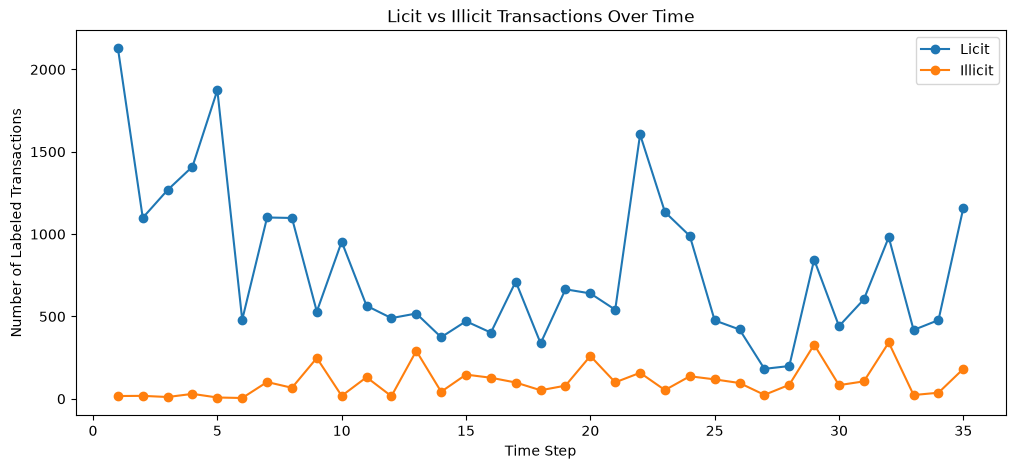

In [255]:
label_time.plot(
    figsize=(12, 5),
    marker="o"
)

plt.xlabel("Time Step")
plt.ylabel("Number of Labeled Transactions")
plt.title("Licit vs Illicit Transactions Over Time")
plt.legend(["Licit", "Illicit"])
plt.show()

**Summary:** Visualizes the table above — illicit counts spike around time_steps 9, 13, 20, and 29–32, while licit counts dominate throughout.

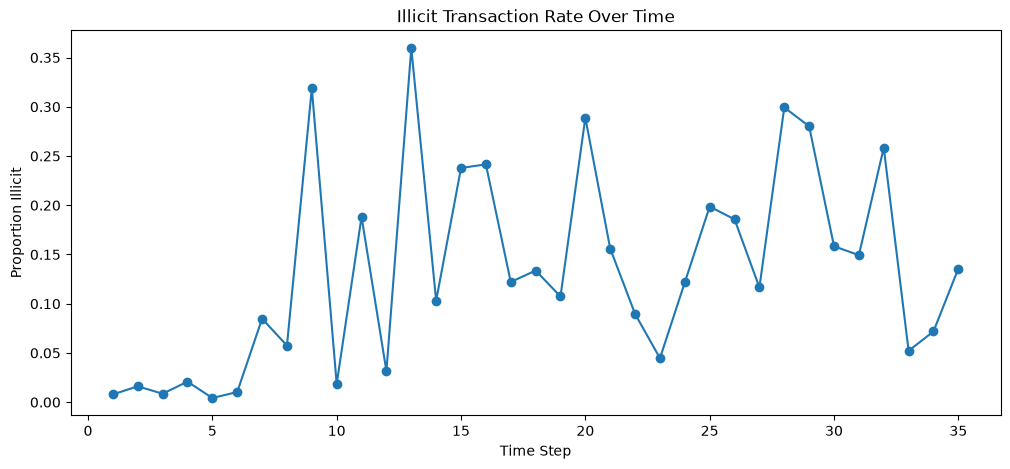

In [256]:
illicit_rate = (
    labeled
    .groupby("time_step")["label"]
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    illicit_rate.index,
    illicit_rate.values,
    marker="o"
)

plt.xlabel("Time Step")
plt.ylabel("Proportion Illicit")
plt.title("Illicit Transaction Rate Over Time")
plt.show()

**Summary:** The illicit rate (illicit / labeled) swings roughly between 0.4% and 36% across time steps — the fraud rate is highly non-stationary. This reinforces the need for a time-aware validation split rather than random k-fold.

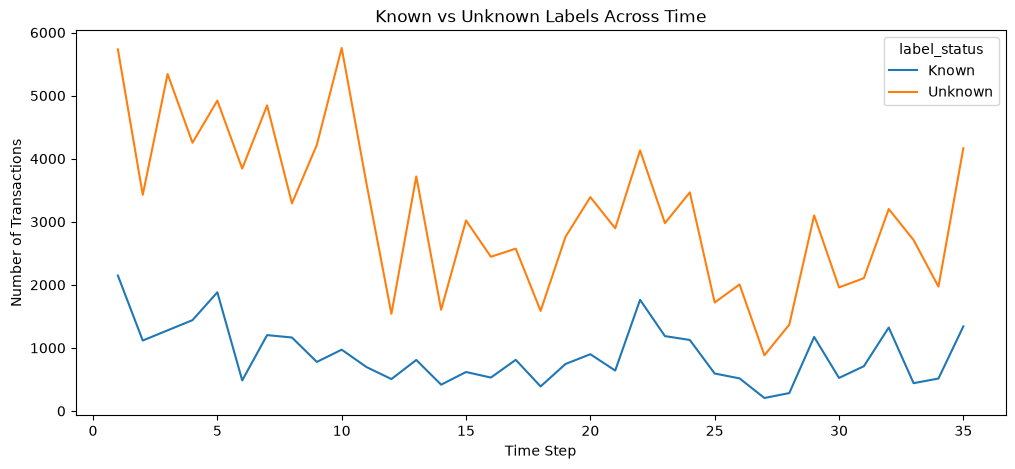

In [257]:
# check whether missing labels are more common in certain time steps
temp = train.copy()

temp["label_status"] = np.where(
    temp["label"].isna(),
    "Unknown",
    "Known"
)

status_time = (
    temp
    .groupby(["time_step", "label_status"])
    .size()
    .unstack(fill_value=0)
)

status_time.plot(
    figsize=(12, 5)
)

plt.xlabel("Time Step")
plt.ylabel("Number of Transactions")
plt.title("Known vs Unknown Labels Across Time")
plt.show()

**Summary:** Known-label counts per time step range from ~1,117 to ~1,882, while unknown counts run several times higher throughout every time step — labeling is sparse everywhere, not just in a few windows.

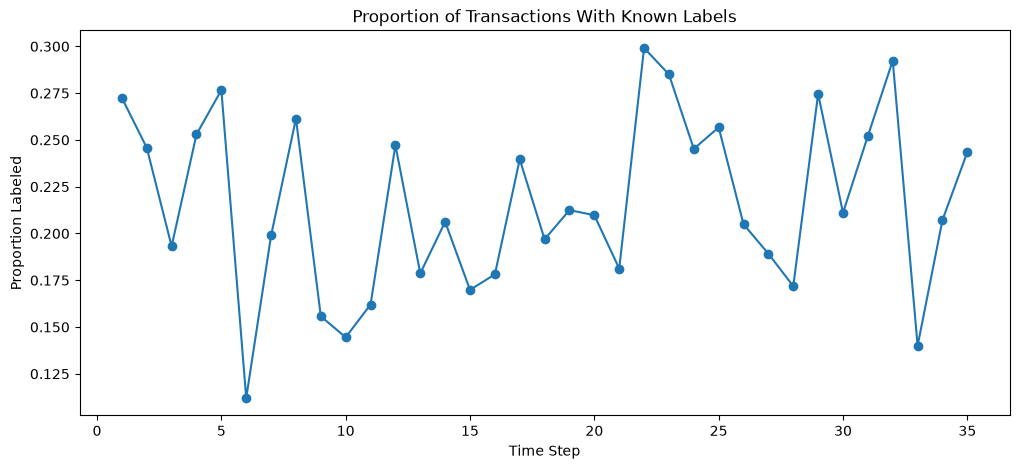

In [258]:
known_rate = (
    temp
    .assign(known=temp["label"].notna())
    .groupby("time_step")["known"]
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    known_rate.index,
    known_rate.values,
    marker="o"
)

plt.xlabel("Time Step")
plt.ylabel("Proportion Labeled")
plt.title("Proportion of Transactions With Known Labels")
plt.show()

**Summary:** The proportion of rows with a known label ranges from about 11.2% to 29.9% across time steps — labeling coverage itself varies over time, so don't assume a fixed ~22% labeled rate applies everywhere.

### 1.4 Feature distributions, redundancy and drift

In [259]:
feature_summary = train[feature_cols].describe().T

display(feature_summary.head(20))

,count,mean,std,min,25%,50%,75%,max
feat_1,141772.0,0.018390,1.119660,-0.172983,-0.172436,-0.168768,-0.135555,71.681966
feat_2,141772.0,-0.108169,0.395017,-0.210553,-0.184668,-0.158783,-0.107012,25.674475
feat_3,141772.0,-0.300165,0.961251,-1.756361,-1.201369,-0.646376,0.463609,2.128587
feat_4,141772.0,-0.002866,0.990140,-0.121970,-0.121970,-0.121970,-0.046932,49.027598
feat_5,141772.0,0.000438,1.113030,-0.063725,-0.043875,-0.043875,-0.043875,260.090707
feat_6,141772.0,-0.005162,0.994618,-0.113002,-0.113002,-0.113002,-0.113002,54.565178
feat_7,141772.0,0.006491,0.956036,-0.061584,-0.061584,-0.061584,-0.061584,113.440873
feat_8,141772.0,0.019083,1.129079,-0.163646,-0.163515,-0.161930,-0.138658,73.354565
feat_9,141772.0,0.018294,1.120331,-0.169460,-0.168983,-0.165824,-0.136658,72.318396
feat_10,141772.0,-0.000565,0.894260,-0.049707,-0.049707,-0.049707,-0.049707,189.186944


**Summary:** Features are already roughly standardized (mean of per-feature means ≈ -0.035, average std ≈ 0.97), consistent with PCA-derived anonymized inputs. However, some columns have extreme outliers (feature values up to ~289 while most sit in [-2, 2]) — consider robust scaling, winsorizing, or outlier capping before modeling.

In [260]:
# check for highly correlated (redundant) features
corr = train[feature_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

high_corr_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={0: "abs_corr", "level_0": "feature_1", "level_1": "feature_2"})
)
high_corr_pairs = high_corr_pairs[high_corr_pairs["abs_corr"] > 0.98].sort_values(
    "abs_corr", ascending=False
)

print("Feature pairs with |correlation| > 0.98:", len(high_corr_pairs))
display(high_corr_pairs.head(15))

Feature pairs with |correlation| > 0.98: 73


,feature_1,feature_2,abs_corr
3824,feat_24,feat_30,1.000000
9634,feat_59,feat_65,1.000000
3658,feat_23,feat_29,1.000000
9800,feat_60,feat_66,1.000000
9966,feat_61,feat_67,1.000000
3990,feat_25,feat_31,1.000000
3492,feat_22,feat_28,1.000000
9468,feat_58,feat_64,0.999992
4156,feat_26,feat_32,0.999506
4322,feat_27,feat_33,0.999490


**Summary:** 73 feature pairs have |correlation| > 0.98 (e.g. `feat_8`/`feat_1`, `feat_11`/`feat_8`) — meaningful multicollinearity among the 165 features. Consider dropping one from each near-duplicate pair, or applying PCA/regularization (L1/L2), to reduce redundancy before modeling.

This count uses a strict 0.98 cut to show how many features are near-duplicates. The pruning rule in section 4 uses 0.9, which tested better than 0.98 (82 vs 101 features kept); section 4.3 compares the two.

In [261]:
target_corr = (
    labeled[feature_cols + ["label"]]
    .corr()["label"]
    .drop("label")
    .abs()
    .sort_values(ascending=False)
)

display(target_corr.head(20))

feat_53     0.307551
feat_89     0.266436
feat_55     0.261658
feat_90     0.256831
feat_91     0.223915
feat_148    0.196755
feat_150    0.186980
feat_52     0.186078
feat_142    0.180250
feat_54     0.179958
feat_103    0.169814
feat_114    0.169317
feat_112    0.169016
feat_101    0.167378
feat_100    0.165227
feat_154    0.152275
feat_136    0.152225
feat_156    0.141680
feat_75     0.138924
feat_59     0.138861
Name: label, dtype: float64

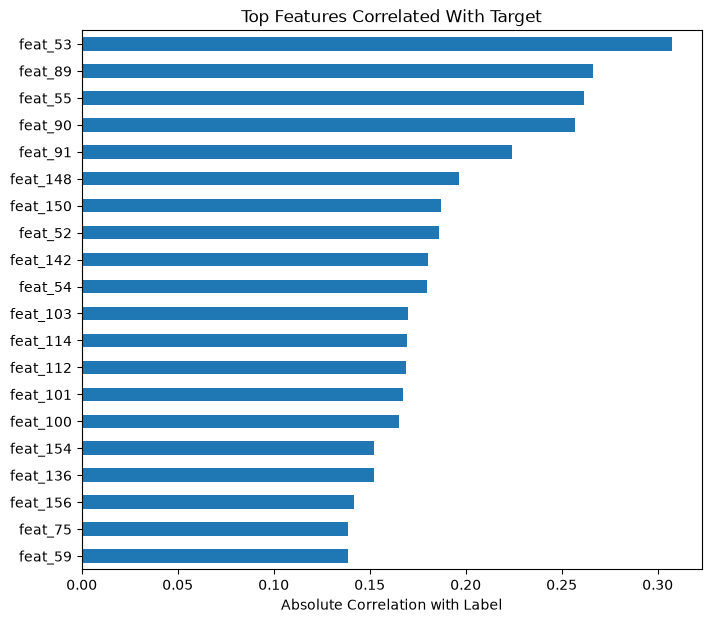

In [262]:
target_corr.head(20).sort_values().plot(
    kind="barh",
    figsize=(8, 7)
)

plt.xlabel("Absolute Correlation with Label")
plt.title("Top Features Correlated With Target")
plt.show()

**Summary:** No single feature is strongly correlated with the label: the strongest is `feat_53` (|r| = 0.31), followed by
`feat_89`, `feat_55` and `feat_90` (0.26-0.27). Signal is spread across many weak features, which suits tree ensembles.

In [263]:
drift = pd.DataFrame({
    "train_mean": train[feature_cols].mean(),
    "test_mean": test[feature_cols].mean(),
    "train_std": train[feature_cols].std(),
    "test_std": test[feature_cols].std()
})

drift["standardized_mean_difference"] = (
    (drift["test_mean"] - drift["train_mean"]).abs()
    /
    (drift["train_std"] + 1e-8)
)

drift = drift.sort_values(
    "standardized_mean_difference",
    ascending=False
)

display(drift.head(20))

,train_mean,test_mean,train_std,test_std,standardized_mean_difference
feat_109,-0.136243,1.004629,0.297970,2.794777,3.828821
feat_106,-0.122392,0.886668,0.270861,2.880821,3.725384
feat_107,-0.141114,1.123706,0.386336,2.671487,3.273890
feat_101,-0.528138,1.185889,0.696534,0.252446,2.460797
feat_103,-0.527069,1.184195,0.698339,0.253007,2.450477
feat_100,-0.521413,1.172057,0.710936,0.254548,2.382029
feat_136,-0.486554,1.089906,0.742283,0.565598,2.123799
feat_139,-0.472526,1.083157,0.767873,0.586330,2.025965
feat_2,-0.108169,0.607044,0.395017,2.507116,1.810587
feat_137,-0.416717,0.991116,0.855626,0.644536,1.645383


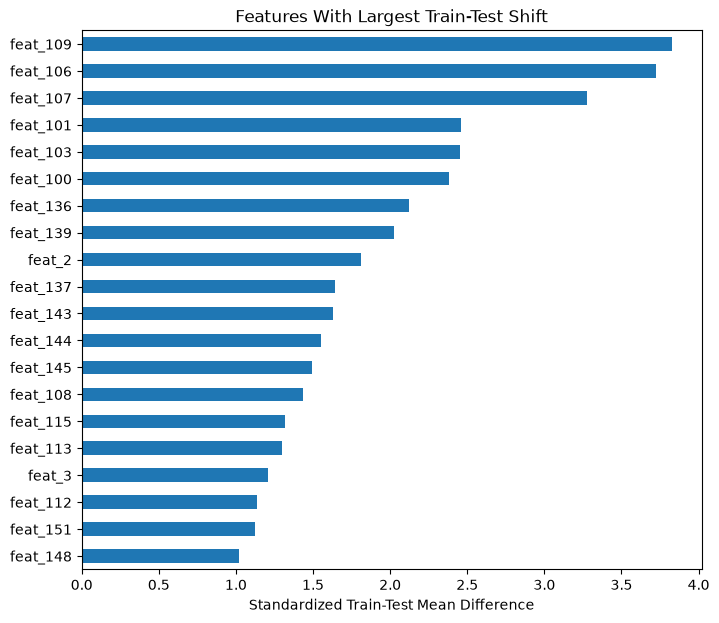

In [264]:
drift.head(20)["standardized_mean_difference"].sort_values().plot(
    kind="barh",
    figsize=(8, 7)
)

plt.xlabel("Standardized Train-Test Mean Difference")
plt.title("Features With Largest Train-Test Shift")
plt.show()

**Summary:** Several features shift sharply between train (1-35) and test (36-49). `feat_109`, `feat_106` and `feat_107`
have test means more than 3 train standard deviations higher, with much wider spread. `feat_101`, `feat_103`, `feat_100`,
`feat_136` and `feat_139` move by more than 2 standard deviations: their per-period means rise steadily with `time_step`, so
they act as time proxies. The model has to rank transactions well in periods it has never seen.

### 1.5 The transaction graph

In [265]:
print("Number of edges:", len(edges))

nodes_in_graph = set(edges["txId1"]) | set(edges["txId2"])

print("Number of unique graph nodes:", len(nodes_in_graph))

all_nodes = set(train["txId"]) | set(test["txId"])

print("Total train + test nodes:", len(all_nodes))

print(
    "Nodes appearing in graph:",
    len(all_nodes & nodes_in_graph)
)

print(
    "Nodes not appearing in graph:",
    len(all_nodes - nodes_in_graph)
)

Number of edges: 234355
Number of unique graph nodes: 203769
Total train + test nodes: 157101
Nodes appearing in graph: 157101
Nodes not appearing in graph: 0


In [266]:
out_degree = edges.groupby("txId1").size()
in_degree = edges.groupby("txId2").size()

eda_degree = pd.DataFrame(
    index=list(all_nodes)
)

eda_degree["in_degree"] = (
    eda_degree.index
    .map(in_degree)
    .fillna(0)
)

eda_degree["out_degree"] = (
    eda_degree.index
    .map(out_degree)
    .fillna(0)
)

eda_degree["total_degree"] = (
    eda_degree["in_degree"]
    + eda_degree["out_degree"]
)

display(eda_degree.head())

,in_degree,out_degree,total_degree
272105479,0.0,1.0,1.0
395313180,1.0,1.0,2.0
339738664,1.0,0.0,1.0
48234540,0.0,1.0,1.0
31981613,1.0,1.0,2.0


In [267]:
display(
    eda_degree[
        ["in_degree", "out_degree", "total_degree"]
    ].describe()
)

,in_degree,out_degree,total_degree
count,157101.000000,157101.000000,157101.000000
mean,1.235664,1.158217,2.393880
std,4.341658,1.944670,4.745562
min,0.000000,0.000000,1.000000
25%,0.000000,1.000000,1.000000
50%,1.000000,1.000000,2.000000
75%,1.000000,1.000000,2.000000
max,284.000000,472.000000,473.000000


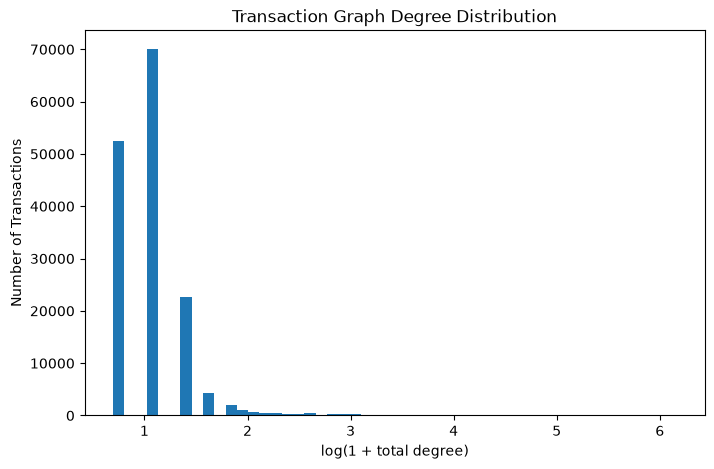

In [268]:
plt.figure(figsize=(8, 5))

plt.hist(
    np.log1p(eda_degree["total_degree"]),
    bins=50
)

plt.xlabel("log(1 + total degree)")
plt.ylabel("Number of Transactions")
plt.title("Transaction Graph Degree Distribution")

plt.show()

In [269]:
eda_degree = (
    eda_degree
    .reset_index()
    .rename(columns={"index": "txId"})
)

labeled_graph = labeled.merge(
    eda_degree,
    on="txId",
    how="left"
)

display(
    labeled_graph
    .groupby("label")[
        ["in_degree", "out_degree", "total_degree"]
    ]
    .agg(["mean", "median", "max"])
)

in_degree               out_degree               total_degree         \
           mean median    max       mean median    max         mean median   
label                                                                        
0      1.830379    1.0  284.0   1.148382    1.0  472.0     2.978761    2.0   
1      1.254391    1.0  173.0   0.754665    1.0    2.0     2.009056    1.0   

              
         max  
label         
0      473.0  
1      173.0

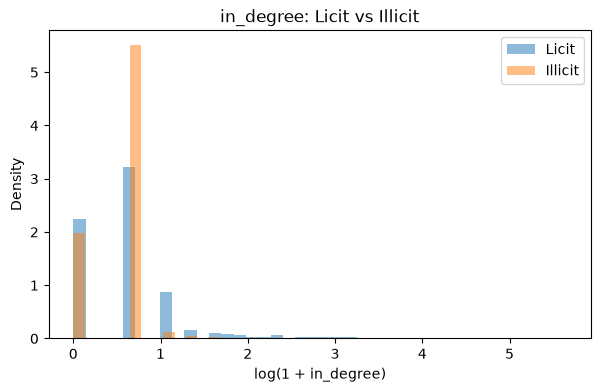

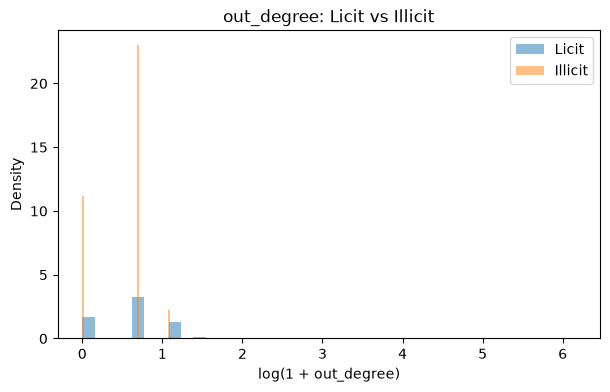

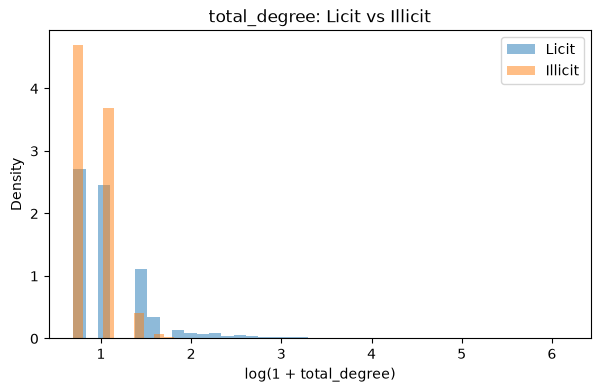

In [270]:
for col in ["in_degree", "out_degree", "total_degree"]:

    plt.figure(figsize=(7, 4))

    for label, name in [(0, "Licit"), (1, "Illicit")]:

        values = labeled_graph.loc[
            labeled_graph["label"] == label,
            col
        ]

        plt.hist(
            np.log1p(values),
            bins=40,
            alpha=0.5,
            density=True,
            label=name
        )

    plt.xlabel(f"log(1 + {col})")
    plt.ylabel("Density")
    plt.title(f"{col}: Licit vs Illicit")
    plt.legend()

    plt.show()

**Summary:** Every train and test transaction appears in the edge list (203,769 nodes in total, including nodes outside
train/test). Degree is small and skewed (median 2). Illicit transactions have **lower** degree than licit ones (mean total
degree 2.01 vs 2.98), and their out-degree never exceeds 2, while licit transactions reach 472: graph structure carries signal.

In [271]:
time_map = pd.concat([
    train[["txId", "time_step"]],
    test[["txId", "time_step"]]
]).drop_duplicates("txId")

edge_time = (
    edges
    .merge(
        time_map.rename(
            columns={
                "txId": "txId1",
                "time_step": "source_time"
            }
        ),
        on="txId1",
        how="left"
    )
    .merge(
        time_map.rename(
            columns={
                "txId": "txId2",
                "time_step": "dest_time"
            }
        ),
        on="txId2",
        how="left"
    )
)

edge_time["time_difference"] = (
    edge_time["dest_time"]
    - edge_time["source_time"]
)

print(edge_time["time_difference"].value_counts().sort_index())

print(
    "\nEdges apparently going backward:",
    (edge_time["time_difference"] < 0).sum()
)

print(
    "Edges within same time step:",
    (edge_time["time_difference"] == 0).sum()
)

print(
    "Edges crossing time steps:",
    (edge_time["time_difference"] > 0).sum()
)

time_difference
0.0    175918
Name: count, dtype: int64

Edges apparently going backward: 0
Edges within same time step: 175918
Edges crossing time steps: 0


In [272]:
node_split = {}

for tx in train["txId"]:
    node_split[tx] = "train"

for tx in test["txId"]:
    node_split[tx] = "test"

edge_split = edges.copy()

edge_split["source_split"] = edge_split["txId1"].map(node_split)
edge_split["dest_split"] = edge_split["txId2"].map(node_split)

display(
    pd.crosstab(
        edge_split["source_split"],
        edge_split["dest_split"]
    )
)

dest_split,test,train
source_split,,
test,12724,0
train,0,163194


In [273]:
# graph structure: node coverage, degree distribution, and edge time behavior
all_tx_in_edges = set(edges["txId1"]) | set(edges["txId2"])

print("Unique tx involved in edges:", len(all_tx_in_edges))
print("Train txId covered by edges:", train["txId"].isin(all_tx_in_edges).sum(), "/", len(train))
print("Test txId covered by edges:", test["txId"].isin(all_tx_in_edges).sum(), "/", len(test))

degree = pd.concat([edges["txId1"], edges["txId2"]]).value_counts()
print("\nDegree stats -> mean: {:.2f}, median: {:.0f}, max: {}".format(
    degree.mean(), degree.median(), degree.max()
))

# do edges connect transactions within the same time_step, or across time?
time_map = pd.concat([
    train.set_index("txId")["time_step"],
    test.set_index("txId")["time_step"],
])
e = edges.copy()
e["t1"] = e["txId1"].map(time_map)
e["t2"] = e["txId2"].map(time_map)
both_time_known = e.dropna(subset=["t1", "t2"])

print("\nEdges with both endpoints' time_step known:", len(both_time_known), "/", len(e))
print("Fraction where t2 == t1 (same time step):", (both_time_known["t2"] == both_time_known["t1"]).mean())

Unique tx involved in edges: 203769
Train txId covered by edges: 141772 / 141772
Test txId covered by edges: 15329 / 15329

Degree stats -> mean: 2.30, median: 2, max: 473

Edges with both endpoints' time_step known: 175918 / 234355
Fraction where t2 == t1 (same time step): 1.0


**Summary:** Every train and test `txId` appears in `edges` (203,769 unique tx total, 100% coverage — no isolated nodes), so graph-based features can be built for the whole dataset. Degree is skewed (mean 2.3, median 2, max 473 — a few hub transactions). Notably, **100% of edges connect two transactions in the same `time_step`** — the graph is a set of per-time-step snapshots, not a chain across time. This matters for feature engineering: neighbor-based features should be computed within each `time_step`, not globally.

The cross-tab above also shows that no edge links a train transaction to a test transaction (163,194 train-train and 12,724
test-test edges): the test periods form their own separate graphs.

In [274]:
# label homophily: do connected transactions tend to share the same label?
label_map = train.set_index("txId")["label"]
e = edges.copy()
e["label1"] = e["txId1"].map(label_map)
e["label2"] = e["txId2"].map(label_map)

both_labeled = e.dropna(subset=["label1", "label2"])
same_label_rate = (both_labeled["label1"] == both_labeled["label2"]).mean()

from_illicit = both_labeled[both_labeled["label1"] == 1]
illicit_to_illicit_rate = (from_illicit["label2"] == 1).mean()

print("Edges with both endpoints labeled:", len(both_labeled), "/", len(e))
print("Fraction of those edges connecting two nodes with the SAME label:", round(same_label_rate, 4))
print("Fraction of edges FROM an illicit node that point TO another illicit node:", round(illicit_to_illicit_rate, 4))
print("(compare to overall illicit base rate among labeled tx: {:.4f})".format(
    (labeled["label"] == 1).mean()
))

Edges with both endpoints labeled: 23900 / 234355
Fraction of those edges connecting two nodes with the SAME label: 0.9468
Fraction of edges FROM an illicit node that point TO another illicit node: 0.5598
(compare to overall illicit base rate among labeled tx: 0.1167)


**Summary — this is the most actionable finding in the notebook:** Of the 23,900 edges where both endpoints are labeled, **94.7% connect two transactions with the same label** (strong homophily). Even more striking: an edge starting at an illicit transaction points to another illicit transaction **56.0%** of the time, versus an overall illicit base rate of only **11.7%** among labeled transactions. This means a transaction's neighbors are highly predictive of its own label — engineering graph features (e.g. count/fraction of a node's known-illicit neighbors, or a GNN/label-propagation approach) is likely to substantially outperform using `feat_*` columns alone.

In [275]:
# Combine train + test features
eda_all_tx = pd.concat(
    [
        train[["txId"] + feature_cols],
        test[["txId"] + feature_cols]
    ],
    ignore_index=True
)

# Attach source-node features
edge_feat = edges.merge(
    eda_all_tx,
    left_on="txId1",
    right_on="txId",
    how="inner"
)

edge_feat = edge_feat.drop(columns="txId")

# Rename source features
edge_feat = edge_feat.rename(
    columns={
        col: f"source_{col}"
        for col in feature_cols
    }
)

# Attach destination features
edge_feat = edge_feat.merge(
    eda_all_tx,
    left_on="txId2",
    right_on="txId",
    how="inner"
)

print("Edges with features for both endpoints:", len(edge_feat))

Edges with features for both endpoints: 175918


In [276]:
neighbor_feature_corr = {}

for col in feature_cols:

    source = edge_feat[f"source_{col}"]
    dest = edge_feat[col]

    neighbor_feature_corr[col] = source.corr(dest)

neighbor_feature_corr = (
    pd.Series(neighbor_feature_corr)
    .sort_values(ascending=False)
)

display(neighbor_feature_corr.head(20))

feat_101    0.994693
feat_103    0.991963
feat_100    0.970763
feat_136    0.891019
feat_139    0.839951
feat_115    0.790366
feat_84     0.735765
feat_18     0.717654
feat_19     0.715651
feat_49     0.709600
feat_97     0.702224
feat_46     0.699346
feat_47     0.696482
feat_83     0.695908
feat_40     0.692564
feat_113    0.673826
feat_94     0.673592
feat_43     0.666927
feat_78     0.631707
feat_41     0.627110
dtype: float64

In [277]:
print(
    "Mean same-feature correlation across connected transactions:",
    neighbor_feature_corr.mean()
)

print(
    "Median:",
    neighbor_feature_corr.median()
)

Mean same-feature correlation across connected transactions: 0.276463006002647
Median: 0.18864351273220156


**Summary:** Connected transactions have correlated features (mean same-feature correlation 0.28 across edges, median
0.19). The highest are the time-proxy features (`feat_101` 0.99, `feat_103` 0.99), as expected since every edge stays within one
time step.

In [278]:
constant_features = [c for c in feature_cols if train[c].nunique() <= 1]

print("=" * 60)
print("DATASET SUMMARY")
print("=" * 60)

print(f"""
Train transactions:       {len(train):,}
Test transactions:        {len(test):,}
Features:                 {len(feature_cols)}
Graph edges:              {len(edges):,}

Labeled transactions:     {len(labeled):,}
Unknown transactions:     {len(unlabeled):,}

Licit:                    {(labeled['label'] == 0).sum():,}
Illicit:                  {(labeled['label'] == 1).sum():,}

Illicit rate:             {labeled['label'].mean():.4%}

Train time range:         {train['time_step'].min()} - {train['time_step'].max()}
Test time range:          {test['time_step'].min()} - {test['time_step'].max()}

Constant features:        {len(constant_features)}
Duplicate train IDs:      {train['txId'].duplicated().sum()}
Duplicate test IDs:       {test['txId'].duplicated().sum()}
Duplicate edges:          {edges.duplicated().sum()}
""")

DATASET SUMMARY

Train transactions:       141,772
Test transactions:        15,329
Features:                 165
Graph edges:              234,355

Labeled transactions:     31,235
Unknown transactions:     110,537

Licit:                    27,591
Illicit:                  3,644

Illicit rate:             11.6664%

Train time range:         1 - 35
Test time range:          36 - 49

Constant features:        0
Duplicate train IDs:      0
Duplicate test IDs:       0
Duplicate edges:          0



### EDA takeaways for modelling

1. **Imbalanced target** (11.7% illicit among labelled rows): judge models by AUC, and try class weighting.
2. **Forward-in-time split** (train 1-35, test 36-49) with a **non-stationary illicit rate** (0.4%-36% per period): validation
   must be temporal, never random k-fold.
3. **Redundant features** (73 pairs with |r| > 0.98) and **time-proxy features** that drift strongly into the test periods.
4. **Strong label homophily** in the graph (94.7% of labelled edges join same-label transactions): neighbour-based features
   should help.
5. **Each time step is its own graph**, so graph features never mix information across periods.

## 2. Baseline models: tabular features only, temporal cross-validation

**Goal:** establish a tabular-features-only baseline AUC, using a validation scheme that respects the dataset's time structure, so that later graph-feature additions can be judged against a fair number.

From `02_baseline_model.ipynb`.

**Why not random k-fold?** The EDA above showed:
- The illicit rate swings from ~0.4% to ~36% across `time_step`s — the target distribution is non-stationary.
- Train (`time_step` 1-35) and the real Kaggle test set (`time_step` 36-49) are a strict forward-in-time split with zero overlap.
- Several features show real train→test distribution shift over time (e.g. `feat_109`, `feat_106`, `feat_2`).

Random k-fold CV would shuffle time steps together, letting the model "see the future" within a fold and producing an overly optimistic, unrealistic AUC. Instead we use **grouped walk-forward CV**: fold boundaries are placed between whole `time_step`s (never splitting a time step across train/val), and each validation block only ever comes *after* its training block in time — mirroring exactly how the model will be judged on the real test set.

### 2.1 Temporal (grouped, expanding-window) cross-validation

We apply `TimeSeriesSplit` to the **sorted unique `time_step` values** (not to rows). This gives fold boundaries that fall between whole time steps, so:
- No time step is ever split across train and validation within a fold.
- Every validation block is strictly later in time than its training block (expanding window: fold *k* trains on all time steps before the block, validates on the next block).
- We hold out the **final chunk of time steps entirely** as a locked final validation set that no fold or hyperparameter choice ever touches — the closest in-sample proxy we have for the real test set's "future" time steps (36-49).

In [279]:
unique_times = np.sort(labeled["time_step"].unique())

N_HOLDOUT_TIMES = 5  # last 5 labeled time steps, locked away
cv_times = unique_times[:-N_HOLDOUT_TIMES]
holdout_times = unique_times[-N_HOLDOUT_TIMES:]

print(f"CV time steps:      {cv_times.min()}-{cv_times.max()} ({len(cv_times)} steps)")
print(f"Holdout time steps: {holdout_times.min()}-{holdout_times.max()} ({len(holdout_times)} steps)")

N_SPLITS = 4
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

folds = []
for fold_i, (train_idx, val_idx) in enumerate(tscv.split(cv_times)):
    train_times = cv_times[train_idx]
    val_times = cv_times[val_idx]
    folds.append((train_times, val_times))
    print(
        f"Fold {fold_i}: train time_steps {train_times.min()}-{train_times.max()} "
        f"({len(train_times)} steps) -> val time_steps {val_times.min()}-{val_times.max()} "
        f"({len(val_times)} steps)"
    )

CV time steps:      1-30 (30 steps)
Holdout time steps: 31-35 (5 steps)
Fold 0: train time_steps 1-6 (6 steps) -> val time_steps 7-12 (6 steps)
Fold 1: train time_steps 1-12 (12 steps) -> val time_steps 13-18 (6 steps)
Fold 2: train time_steps 1-18 (18 steps) -> val time_steps 19-24 (6 steps)
Fold 3: train time_steps 1-24 (24 steps) -> val time_steps 25-30 (6 steps)


### 2.2 XGBoost baseline

Using `scale_pos_weight` to account for the ~7.6:1 licit:illicit imbalance found in EDA, and AUC as the eval metric (appropriate given the imbalance — accuracy would be misleading).

In [280]:
def run_temporal_cv(make_model, folds, data, feature_cols, label_col="label"):
    fold_scores = []
    for fold_i, (train_times, val_times) in enumerate(folds):
        train_fold = data[data["time_step"].isin(train_times)]
        val_fold = data[data["time_step"].isin(val_times)]

        X_train, y_train = train_fold[feature_cols], train_fold[label_col]
        X_val, y_val = val_fold[feature_cols], val_fold[label_col]

        model = make_model(y_train)
        model.fit(X_train, y_train)

        # Predictions
        val_pred_proba = model.predict_proba(X_val)[:, 1]
        val_pred = model.predict(X_val)

        # Metrics
        auc = roc_auc_score(y_val, val_pred_proba)
        f1_weighted = f1_score(y_val, val_pred, average="weighted")
        precision = precision_score(y_val, val_pred, zero_division=0)
        recall = recall_score(y_val, val_pred, zero_division=0)

        fold_scores.append({
            "auc": auc,
            "f1_weighted": f1_weighted,
            "precision": precision,
            "recall": recall,
        })

        print(
            f"Fold {fold_i}: train n={len(train_fold):>5} (illicit={y_train.mean():>6.2%}), "
            f"val n={len(val_fold):>5} (illicit={y_val.mean():>6.2%})\n"
            f"  AUC={auc:.4f}, "
            f"F1-weighted={f1_weighted:.4f}, "
            f"Precision={precision:.4f}, "
            f"Recall={recall:.4f}"
        )

    # Overall CV results
    auc_scores = np.array([x["auc"] for x in fold_scores])
    f1_scores = np.array([x["f1_weighted"] for x in fold_scores])
    precision_scores = np.array([x["precision"] for x in fold_scores])
    recall_scores = np.array([x["recall"] for x in fold_scores])

    mean_auc = auc_scores.mean()
    std_auc = auc_scores.std()
    worst_auc = auc_scores.min()

    print("\n=== Mean CV Performance ===")
    print(f"AUC:         {mean_auc:.4f} (std: {std_auc:.4f}, worst: {worst_auc:.4f})")
    print(f"F1-weighted: {f1_scores.mean():.4f} (std: {f1_scores.std():.4f})")
    print(f"Precision:   {precision_scores.mean():.4f} (std: {precision_scores.std():.4f})")
    print(f"Recall:      {recall_scores.mean():.4f} (std: {recall_scores.std():.4f})")
    print(f"\nmean_auc={mean_auc:.4f}  std_auc={std_auc:.4f}  worst_auc={worst_auc:.4f}")

    return fold_scores


def make_xgb_model(y_train):
    licit_count = np.sum(y_train == 0)
    illicit_count = np.sum(y_train == 1)

    pos_weight = licit_count / illicit_count if illicit_count > 0 else 50.0
    return xgb.XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=pos_weight,
        eval_metric="auc",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


print("=== XGBoost: temporal CV ===")
xgb_fold_scores = run_temporal_cv(make_xgb_model, folds, labeled, feature_cols)

=== XGBoost: temporal CV ===


Fold 0: train n= 8350 (illicit= 1.07%), val n= 5320 (illicit=10.94%)
  AUC=0.9622, F1-weighted=0.9731, Precision=0.9890, Recall=0.7749
Fold 1: train n=13670 (illicit= 4.91%), val n= 3574 (illicit=21.26%)
  AUC=0.9969, F1-weighted=0.9888, Precision=0.9762, Recall=0.9711
Fold 2: train n=17244 (illicit= 8.30%), val n= 6362 (illicit=12.39%)
  AUC=0.9369, F1-weighted=0.9633, Precision=0.9686, Recall=0.7437
Fold 3: train n=23606 (illicit= 9.40%), val n= 3299 (illicit=22.28%)
  AUC=0.9970, F1-weighted=0.9818, Precision=0.9604, Recall=0.9578

=== Mean CV Performance ===
AUC:         0.9732 (std: 0.0253, worst: 0.9369)
F1-weighted: 0.9767 (std: 0.0096)
Precision:   0.9736 (std: 0.0105)
Recall:      0.8619 (std: 0.1033)

mean_auc=0.9732  std_auc=0.0253  worst_auc=0.9369


### 2.3 LightGBM baseline

Same folds, same imbalance handling (`scale_pos_weight`), so the two models are directly comparable.

In [281]:
def make_lgb_model(y_train):
    licit_count = np.sum(y_train == 0)
    illicit_count = np.sum(y_train == 1)
    
    pos_weight = licit_count / illicit_count if illicit_count > 0 else 50.0
    return lgb.LGBMClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        scale_pos_weight=pos_weight,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1,
    )


print("=== LightGBM: temporal CV ===")
lgb_fold_scores = run_temporal_cv(make_lgb_model, folds, labeled, feature_cols)

=== LightGBM: temporal CV ===
Fold 0: train n= 8350 (illicit= 1.07%), val n= 5320 (illicit=10.94%)
  AUC=0.9604, F1-weighted=0.9720, Precision=0.9889, Recall=0.7663
Fold 1: train n=13670 (illicit= 4.91%), val n= 3574 (illicit=21.26%)
  AUC=0.9972, F1-weighted=0.9902, Precision=0.9840, Recall=0.9697
Fold 2: train n=17244 (illicit= 8.30%), val n= 6362 (illicit=12.39%)
  AUC=0.9252, F1-weighted=0.9614, Precision=0.9618, Recall=0.7348
Fold 3: train n=23606 (illicit= 9.40%), val n= 3299 (illicit=22.28%)
  AUC=0.9963, F1-weighted=0.9815, Precision=0.9604, Recall=0.9565

=== Mean CV Performance ===
AUC:         0.9698 (std: 0.0297, worst: 0.9252)
F1-weighted: 0.9763 (std: 0.0107)
Precision:   0.9738 (std: 0.0128)
Recall:      0.8568 (std: 0.1070)

mean_auc=0.9698  std_auc=0.0297  worst_auc=0.9252


In [282]:
xgb_summary = pd.DataFrame(xgb_fold_scores).add_prefix("xgboost_")
lgb_summary = pd.DataFrame(lgb_fold_scores).add_prefix("lightgbm_")

cv_summary = pd.concat([xgb_summary, lgb_summary], axis=1)
cv_summary.index = [f"fold_{i}" for i in range(len(cv_summary))]
fold_rows = cv_summary.index.tolist()

cv_summary.loc["mean"] = cv_summary.mean(numeric_only=True)
cv_summary.loc["std"] = cv_summary.loc[fold_rows].std(numeric_only=True)

display(cv_summary)

,xgboost_auc,xgboost_f1_weighted,xgboost_precision,xgboost_recall,lightgbm_auc,lightgbm_f1_weighted,lightgbm_precision,lightgbm_recall
fold_0,0.962158,0.973052,0.989035,0.774914,0.960370,0.971996,0.988914,0.766323
fold_1,0.996877,0.988797,0.976190,0.971053,0.997170,0.990181,0.983979,0.969737
fold_2,0.936878,0.963261,0.968595,0.743655,0.925213,0.961393,0.961794,0.734772
fold_3,0.996975,0.981804,0.960437,0.957823,0.996347,0.981496,0.960383,0.956463
mean,0.973222,0.976729,0.973564,0.861861,0.969775,0.976267,0.973767,0.856824
std,0.029252,0.011050,0.012156,0.119253,0.034306,0.012388,0.014790,0.123510


### 2.4 XGBoost Unweighted (scale_pos_weight = 1)

In [283]:
def make_xgb_unweighted(y_train):
    return xgb.XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=1,
        eval_metric="auc",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

xgb_unweighted_scores = run_temporal_cv(
    make_xgb_unweighted,
    folds,
    labeled,
    feature_cols
)

Fold 0: train n= 8350 (illicit= 1.07%), val n= 5320 (illicit=10.94%)
  AUC=0.9667, F1-weighted=0.9518, Precision=0.9944, Recall=0.6065
Fold 1: train n=13670 (illicit= 4.91%), val n= 3574 (illicit=21.26%)
  AUC=0.9965, F1-weighted=0.9893, Precision=0.9959, Recall=0.9539
Fold 2: train n=17244 (illicit= 8.30%), val n= 6362 (illicit=12.39%)
  AUC=0.9420, F1-weighted=0.9603, Precision=0.9842, Recall=0.7119
Fold 3: train n=23606 (illicit= 9.40%), val n= 3299 (illicit=22.28%)
  AUC=0.9967, F1-weighted=0.9795, Precision=0.9771, Recall=0.9306

=== Mean CV Performance ===
AUC:         0.9755 (std: 0.0228, worst: 0.9420)
F1-weighted: 0.9702 (std: 0.0149)
Precision:   0.9879 (std: 0.0077)
Recall:      0.8008 (std: 0.1466)

mean_auc=0.9755  std_auc=0.0228  worst_auc=0.9420


In [284]:
weighted_xgb_auc = pd.Series([score["auc"] for score in xgb_fold_scores])
unweighted_xgb_auc = pd.Series([score["auc"] for score in xgb_unweighted_scores])

print("Weighted XGB AUC:  ", weighted_xgb_auc.mean())
print("Unweighted XGB AUC:", unweighted_xgb_auc.mean())

print("Weighted XGB worst AUC:  ", weighted_xgb_auc.min())
print("Unweighted XGB worst AUC:", unweighted_xgb_auc.min())

Weighted XGB AUC:   0.9732219994961147
Unweighted XGB AUC: 0.9755089466566861
Weighted XGB worst AUC:   0.9368781179479053
Unweighted XGB worst AUC: 0.9420421409043801


### 2.5 LightGBM Unweighted (scale_pos_weight = 1)

In [285]:
def make_lgb_unweighted(y_train):
    return lgb.LGBMClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        scale_pos_weight=1,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1
    )
lgb_unweighted_scores = run_temporal_cv(
    make_lgb_unweighted,
    folds,
    labeled,
    feature_cols
)

Fold 0: train n= 8350 (illicit= 1.07%), val n= 5320 (illicit=10.94%)
  AUC=0.9679, F1-weighted=0.9711, Precision=0.9910, Recall=0.7577
Fold 1: train n=13670 (illicit= 4.91%), val n= 3574 (illicit=21.26%)
  AUC=0.9968, F1-weighted=0.9913, Precision=0.9959, Recall=0.9632
Fold 2: train n=17244 (illicit= 8.30%), val n= 6362 (illicit=12.39%)
  AUC=0.9381, F1-weighted=0.9595, Precision=0.9875, Recall=0.7043
Fold 3: train n=23606 (illicit= 9.40%), val n= 3299 (illicit=22.28%)
  AUC=0.9970, F1-weighted=0.9789, Precision=0.9798, Recall=0.9252

=== Mean CV Performance ===
AUC:         0.9749 (std: 0.0243, worst: 0.9381)
F1-weighted: 0.9752 (std: 0.0116)
Precision:   0.9886 (std: 0.0059)
Recall:      0.8376 (std: 0.1091)

mean_auc=0.9749  std_auc=0.0243  worst_auc=0.9381


In [286]:
weighted_lgb_auc = pd.Series([score["auc"] for score in lgb_fold_scores])
unweighted_lgb_auc = pd.Series([score["auc"] for score in lgb_unweighted_scores])

print("Weighted LGB AUC:  ", weighted_lgb_auc.mean())
print("Unweighted LGB AUC:", unweighted_lgb_auc.mean())

print("Weighted LGB worst AUC:  ", weighted_lgb_auc.min())
print("Unweighted LGB worst AUC:", unweighted_lgb_auc.min())

Weighted LGB AUC:   0.9697750034985957
Unweighted LGB AUC: 0.9749363144735383
Weighted LGB worst AUC:   0.9252129630135564
Unweighted LGB worst AUC: 0.938131899555405


### 2.6 LogReg Baseline

In [287]:
def make_logreg_model(y_train):
    # StandardScaler is wrapped in the pipeline so it's fit only on each fold's
    # training rows (inside run_temporal_cv's model.fit call) and applied, not
    # refit, on validation rows -- no scaling leakage across the split.
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE,
            solver="lbfgs",
        ),  # n_jobs dropped: sklearn >=1.8 ignores it for lbfgs and warns
    )


print("=== Logistic Regression: temporal CV ===")
logreg_fold_scores = run_temporal_cv(make_logreg_model, folds, labeled, feature_cols)

=== Logistic Regression: temporal CV ===


Fold 0: train n= 8350 (illicit= 1.07%), val n= 5320 (illicit=10.94%)
  AUC=0.8773, F1-weighted=0.8626, Precision=0.3835, Recall=0.7010
Fold 1: train n=13670 (illicit= 4.91%), val n= 3574 (illicit=21.26%)
  AUC=0.9814, F1-weighted=0.8264, Precision=0.5288, Recall=0.9908
Fold 2: train n=17244 (illicit= 8.30%), val n= 6362 (illicit=12.39%)
  AUC=0.8962, F1-weighted=0.8354, Precision=0.3765, Recall=0.8376
Fold 3: train n=23606 (illicit= 9.40%), val n= 3299 (illicit=22.28%)
  AUC=0.9359, F1-weighted=0.8239, Precision=0.5387, Recall=0.9850

=== Mean CV Performance ===
AUC:         0.9227 (std: 0.0399, worst: 0.8773)
F1-weighted: 0.8371 (std: 0.0154)
Precision:   0.4569 (std: 0.0770)
Recall:      0.8786 (std: 0.1195)

mean_auc=0.9227  std_auc=0.0399  worst_auc=0.8773


### 2.7 RandomForest Baseline Model

In [288]:
def make_rf_model(y_train):
    return RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=0,
    )


print("=== Random Forest: temporal CV ===")
rf_fold_scores = run_temporal_cv(make_rf_model, folds, labeled, feature_cols)

=== Random Forest: temporal CV ===
Fold 0: train n= 8350 (illicit= 1.07%), val n= 5320 (illicit=10.94%)
  AUC=0.9760, F1-weighted=0.9289, Precision=1.0000, Recall=0.4467
Fold 1: train n=13670 (illicit= 4.91%), val n= 3574 (illicit=21.26%)
  AUC=0.9956, F1-weighted=0.9813, Precision=0.9915, Recall=0.9211
Fold 2: train n=17244 (illicit= 8.30%), val n= 6362 (illicit=12.39%)
  AUC=0.9098, F1-weighted=0.9588, Precision=0.9772, Recall=0.7056
Fold 3: train n=23606 (illicit= 9.40%), val n= 3299 (illicit=22.28%)
  AUC=0.9961, F1-weighted=0.9764, Precision=0.9768, Recall=0.9170

=== Mean CV Performance ===
AUC:         0.9694 (std: 0.0353, worst: 0.9098)
F1-weighted: 0.9613 (std: 0.0205)
Precision:   0.9864 (std: 0.0099)
Recall:      0.7476 (std: 0.1943)

mean_auc=0.9694  std_auc=0.0353  worst_auc=0.9098


### 2.8 CatBoost baseline

CatBoost builds symmetric trees and uses "ordered boosting", which is designed to reduce overfitting from fitting each tree on
the rows it is evaluated on. Settings match the XGBoost baseline: 300 iterations, depth 5, learning rate 0.05, no class weighting (the unweighted versions of XGBoost and LightGBM scored best above).

In [289]:
def make_catboost_model(y_train):
    return CatBoostClassifier(
        iterations=300,
        depth=5,
        learning_rate=0.05,
        random_seed=RANDOM_STATE,
        thread_count=-1,
        verbose=0,
    )


print("=== CatBoost: temporal CV ===")
catboost_fold_scores = run_temporal_cv(make_catboost_model, folds, labeled, feature_cols)

=== CatBoost: temporal CV ===
Fold 0: train n= 8350 (illicit= 1.07%), val n= 5320 (illicit=10.94%)
  AUC=0.9597, F1-weighted=0.8995, Precision=0.9758, Recall=0.2766
Fold 1: train n=13670 (illicit= 4.91%), val n= 3574 (illicit=21.26%)
  AUC=0.9962, F1-weighted=0.9904, Precision=0.9986, Recall=0.9566
Fold 2: train n=17244 (illicit= 8.30%), val n= 6362 (illicit=12.39%)
  AUC=0.9253, F1-weighted=0.9604, Precision=0.9877, Recall=0.7107
Fold 3: train n=23606 (illicit= 9.40%), val n= 3299 (illicit=22.28%)
  AUC=0.9953, F1-weighted=0.9751, Precision=0.9781, Recall=0.9102

=== Mean CV Performance ===
AUC:         0.9691 (std: 0.0293, worst: 0.9253)
F1-weighted: 0.9564 (std: 0.0345)
Precision:   0.9850 (std: 0.0090)
Recall:      0.7135 (std: 0.2686)

mean_auc=0.9691  std_auc=0.0293  worst_auc=0.9253


### 2.9 CV performance summary (all tested models)

Mean cross-validated metrics (across the 4 temporal folds above) for every model tested in this notebook, sorted by mean AUC.

In [290]:
cv_metric_sources = {
    "xgboost (weighted)": xgb_fold_scores,
    "xgboost (unweighted)": xgb_unweighted_scores,
    "lightgbm (weighted)": lgb_fold_scores,
    "lightgbm (unweighted)": lgb_unweighted_scores,
    "logreg (balanced)": logreg_fold_scores,
    "random_forest (balanced)": rf_fold_scores,
    "catboost (unweighted)": catboost_fold_scores,
}

cv_summary_rows = []
for name, fold_scores in cv_metric_sources.items():
    aucs = [s["auc"] for s in fold_scores]
    f1s = [s["f1_weighted"] for s in fold_scores]
    precisions = [s["precision"] for s in fold_scores]
    recalls = [s["recall"] for s in fold_scores]
    cv_summary_rows.append({
        "model": name,
        "mean_auc": np.mean(aucs),
        "std_auc": np.std(aucs),
        "worst_auc": np.min(aucs),
        "mean_f1_weighted": np.mean(f1s),
        "mean_precision": np.mean(precisions),
        "mean_recall": np.mean(recalls),
    })

cv_performance_summary = pd.DataFrame(cv_summary_rows).sort_values("mean_auc", ascending=False).reset_index(drop=True)
display(cv_performance_summary)

,model,mean_auc,std_auc,worst_auc,mean_f1_weighted,mean_precision,mean_recall
0,xgboost (unweighted),0.975509,0.022849,0.942042,0.970226,0.987900,0.800754
1,lightgbm (unweighted),0.974936,0.024324,0.938132,0.975189,0.988575,0.837594
2,xgboost (weighted),0.973222,0.025333,0.936878,0.976729,0.973564,0.861861
3,lightgbm (weighted),0.969775,0.029710,0.925213,0.976267,0.973767,0.856824
4,random_forest (balanced),0.969375,0.035329,0.909813,0.961331,0.986366,0.747595
5,catboost (unweighted),0.969143,0.029259,0.925331,0.956361,0.985027,0.713519
6,logreg (balanced),0.922689,0.039945,0.877266,0.837095,0.456860,0.878604


**Summary:** Unweighted XGBoost has the best mean temporal-CV AUC (0.9755) and the best worst fold (0.9420), just ahead of
unweighted LightGBM (0.9749). Class weighting (`scale_pos_weight` ~7.6) did not help the mean AUC of either model. CatBoost
(0.9691) and random forest (0.9694) are close on average but less stable (worst folds 0.9253 and 0.9098, and CatBoost's recall
swings widely between folds), and logistic regression trails clearly (0.9227), with very low precision (0.46) under balanced
weighting.

We built on XGBoost. Later, with graph features and tuning, it also held up best: tuned CatBoost was weaker on the held-out
periods 22-35 (pooled AUC 0.8725 vs 0.9102) and in its worst period (0.6961 vs 0.7748).

### 2.10 Locked final holdout

The CV folds above never touched `time_step`s in `holdout_times` (the last 5 labeled time steps). We now train once on **all** CV time steps and evaluate on this untouched block — the single most realistic proxy we have for how the model will perform on the real, later-in-time Kaggle test set.

Alongside AUC (threshold-free), this also reports **confusion matrix, precision, recall, and F1 at a fixed 0.5 threshold** — the standard `predict_proba > 0.5` cutoff, not tuned on this holdout (tuning the threshold using the same data reported as the final number would leak a decision into the one evaluation meant to stay untouched). A precision-recall curve (threshold-free, in the next cell) shows the fuller trade-off beyond this single cutoff.

In [291]:
cv_train = labeled[labeled["time_step"].isin(cv_times)]
holdout = labeled[labeled["time_step"].isin(holdout_times)]

X_cv_train, y_cv_train = cv_train[feature_cols], cv_train["label"]
X_holdout, y_holdout = holdout[feature_cols], holdout["label"]

CLASSIFICATION_THRESHOLD = 0.5

holdout_results = {}
holdout_predictions = {}
holdout_confusion_matrices = {}

holdout_model_makers = {
    "xgboost_unweighted": make_xgb_unweighted,
    "xgboost_weighted": make_xgb_model,
    "lightgbm_unweighted": make_lgb_unweighted,
    "lightgbm_weighted": make_lgb_model,
    "logreg_balanced": make_logreg_model,
    "random_forest_balanced": make_rf_model,
    "catboost_unweighted": make_catboost_model,
}

for name, make_model in holdout_model_makers.items():
    model = make_model(y_cv_train)
    model.fit(X_cv_train, y_cv_train)
    pred = model.predict_proba(X_holdout)[:, 1]
    pred_label = (pred >= CLASSIFICATION_THRESHOLD).astype(int)

    auc = roc_auc_score(y_holdout, pred)
    f1 = f1_score(y_holdout, pred_label)
    cm = confusion_matrix(y_holdout, pred_label)

    holdout_results[name] = auc
    holdout_predictions[name] = (y_holdout, pred)
    holdout_confusion_matrices[name] = cm

    print(f"=== {name} ===")
    print(f"holdout AUC = {auc:.4f}  (holdout n={len(holdout)}, illicit={y_holdout.mean():.2%})")
    print(f"F1 @ threshold={CLASSIFICATION_THRESHOLD}: {f1:.4f}")
    print(classification_report(y_holdout, pred_label, target_names=["licit", "illicit"], digits=4))

best_model_name = max(holdout_results, key=holdout_results.get)
print(
    f"Highest holdout AUC: "
    f"{best_model_name} "
    f"(AUC={holdout_results[best_model_name]:.4f})"
)

print(
    "\nModel selection should be based primarily "
    "on temporal CV, not the locked holdout. For now, it would be XGB (unweighted)"
)

=== xgboost_unweighted ===
holdout AUC = 0.9976  (holdout n=4330, illicit=15.94%)
F1 @ threshold=0.5: 0.9462
              precision    recall  f1-score   support

       licit     0.9845    0.9959    0.9902      3640
     illicit     0.9769    0.9174    0.9462       690

    accuracy                         0.9834      4330
   macro avg     0.9807    0.9566    0.9682      4330
weighted avg     0.9833    0.9834    0.9832      4330

=== xgboost_weighted ===
holdout AUC = 0.9980  (holdout n=4330, illicit=15.94%)
F1 @ threshold=0.5: 0.9596
              precision    recall  f1-score   support

       licit     0.9964    0.9879    0.9921      3640
     illicit     0.9390    0.9812    0.9596       690

    accuracy                         0.9868      4330
   macro avg     0.9677    0.9845    0.9759      4330
weighted avg     0.9872    0.9868    0.9870      4330

=== lightgbm_unweighted ===
holdout AUC = 0.9980  (holdout n=4330, illicit=15.94%)
F1 @ threshold=0.5: 0.9573
              precis

In [292]:
print("\n=== AUC BY HOLDOUT TIME STEP ===")

for name, (y_holdout_all, pred_all) in holdout_predictions.items():
    print(f"\n{name}")

    for t in holdout_times:
        mask = (holdout["time_step"] == t).values
        y_t = y_holdout_all[mask]
        pred_t = pred_all[mask]

        if y_t.nunique() < 2:
            continue

        auc = roc_auc_score(y_t, pred_t)

        print(
            f"time {t}: "
            f"AUC={auc:.4f}, "
            f"n={len(y_t)}, "
            f"illicit={y_t.mean():.2%}"
        )


=== AUC BY HOLDOUT TIME STEP ===

xgboost_unweighted
time 31: AUC=0.9935, n=710, illicit=14.93%
time 32: AUC=0.9987, n=1323, illicit=25.85%
time 33: AUC=0.9915, n=441, illicit=5.22%
time 34: AUC=0.9994, n=515, illicit=7.18%
time 35: AUC=0.9979, n=1341, illicit=13.57%

xgboost_weighted
time 31: AUC=0.9954, n=710, illicit=14.93%
time 32: AUC=0.9988, n=1323, illicit=25.85%
time 33: AUC=0.9951, n=441, illicit=5.22%
time 34: AUC=0.9997, n=515, illicit=7.18%
time 35: AUC=0.9979, n=1341, illicit=13.57%

lightgbm_unweighted
time 31: AUC=0.9954, n=710, illicit=14.93%
time 32: AUC=0.9992, n=1323, illicit=25.85%
time 33: AUC=0.9933, n=441, illicit=5.22%
time 34: AUC=0.9995, n=515, illicit=7.18%
time 35: AUC=0.9974, n=1341, illicit=13.57%

lightgbm_weighted
time 31: AUC=0.9960, n=710, illicit=14.93%
time 32: AUC=0.9996, n=1323, illicit=25.85%
time 33: AUC=0.9914, n=441, illicit=5.22%
time 34: AUC=0.9998, n=515, illicit=7.18%
time 35: AUC=0.9976, n=1341, illicit=13.57%

logreg_balanced
time 31: AU

#### Confusion matrices (locked holdout, threshold=0.5)

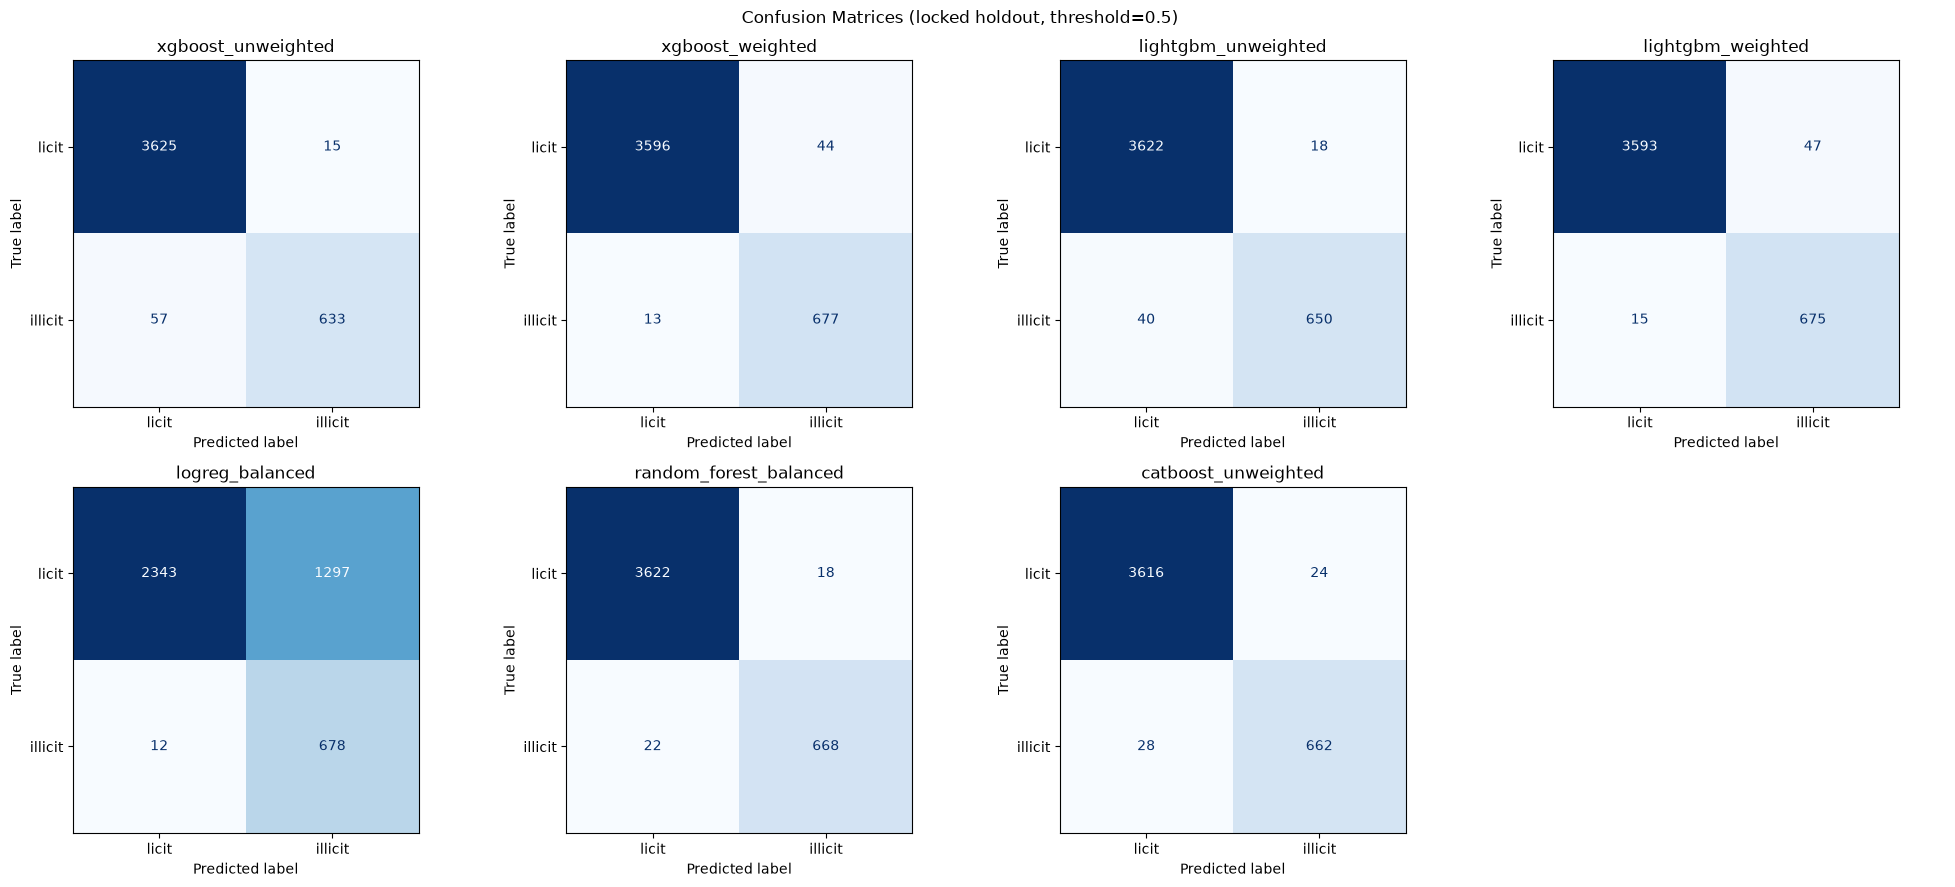

In [293]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))

for ax, (name, cm) in zip(axes.flat, holdout_confusion_matrices.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["licit", "illicit"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

for ax in axes.flat[len(holdout_confusion_matrices):]:
    ax.axis("off")  # 7 models on a 2x4 grid

plt.suptitle("Confusion Matrices (locked holdout, threshold=0.5)")
plt.tight_layout()
plt.show()

#### Precision-recall curve (threshold-free)

The 0.5 cutoff above is one point on this curve. This shows the full trade-off across all thresholds for both models on the same locked holdout, so you can see where a different cutoff would actually land you.

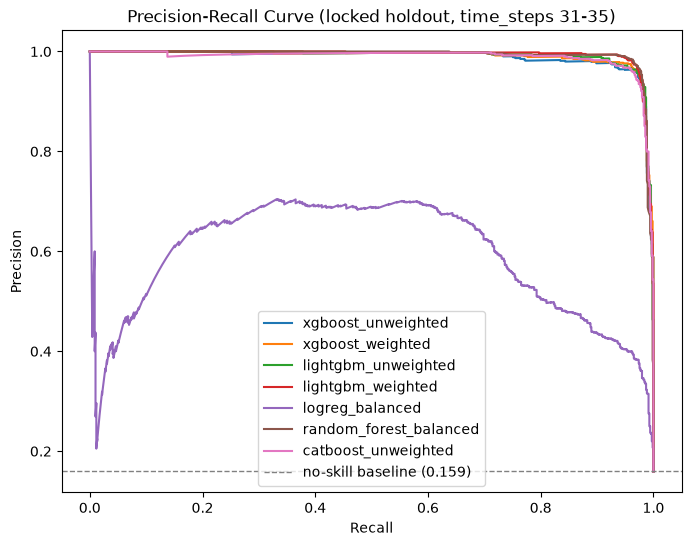

In [294]:
plt.figure(figsize=(8, 6))

for name, (y_holdout, pred) in holdout_predictions.items():
    precision, recall, _ = precision_recall_curve(y_holdout, pred)
    plt.plot(recall, precision, label=name)

baseline_rate = holdout["label"].mean()
plt.axhline(baseline_rate, color="gray", linestyle="--", linewidth=1, label=f"no-skill baseline ({baseline_rate:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (locked holdout, time_steps 31-35)")
plt.legend()
plt.show()

Sanity check: no exact feature vector appears in both the CV training rows and the holdout, so the high holdout AUCs are
not caused by duplicated transactions.

In [295]:
train_hash = pd.util.hash_pandas_object(
    cv_train[feature_cols],
    index=False
)

holdout_hash = pd.util.hash_pandas_object(
    holdout[feature_cols],
    index=False
)

overlap = np.intersect1d(
    train_hash.unique(),
    holdout_hash.unique()
)

print("Exact feature-vector overlap:", len(overlap))
print(
    "Fraction of holdout matching CV train:",
    holdout_hash.isin(overlap).mean()
)

Exact feature-vector overlap: 0
Fraction of holdout matching CV train: 0.0


**Summary:** On the locked holdout (periods 31-35), all five boosted-tree models and the random forest score AUC
0.9976-0.9984, while logistic regression scores 0.9177. With every tree model within 0.001, this window can't separate them;
the temporal CV above is the better guide, and it points to XGBoost, which the rest of this notebook builds on.

### Baseline takeaways and next steps

This baseline uses only the 165 anonymized `feat_*` columns. EDA found strong label homophily in the transaction graph (94.7% of labeled edges connect same-label nodes; an illicit node's neighbor is illicit 56% of the time vs. an 11.7% base rate) — graph features are the next lever to pull:

- Neighbor aggregates per `time_step` (count/fraction of a node's neighbors that are known-illicit, neighbor feature means, in/out-degree).
- Judge every addition against these baseline numbers with a temporal check. Sections 3-4 do this with a stricter test, the **horizon curve**: train on periods 1-21 and score each of 22-35 separately. The single 31-35 holdout above is nearly saturated (every tree model scores about 0.998), so it can no longer tell models apart.

## 3. Graph feature engineering

Three families of graph-derived features, all leak-free by construction:

- **Structural degree** (`in_degree`, `out_degree`, `total_degree`) -- static, label-free, safe to compute once globally.
- **`risk_prob_self`** -- a causal "self-risk" score. For each period `t <= cutoff`, a small XGBoost model is fit only on labels from periods strictly before `t`, then scores period `t`. Periods beyond `cutoff` are all scored by one model frozen at `cutoff` -- exactly mirroring how the real test set (36-49) will be scored by a model frozen at period 35.
- **`component_size`** (optional, `USE_COMPONENT_SIZE`) -- number of nodes in the node's connected component (edges treated as undirected). Static and label-free like degree, so it is computed once globally. Illicit transactions sit in noticeably smaller components (Cohen's d -0.75 in `03c`), and it was the only one of ~15 hand-built structural features that helped on the horizon curve.
- **Neighbor-risk aggregates** (`neighbor_risk_mean/max/high_frac`, plus coverage diagnostics) -- summarize a node's 1-hop neighbors' own `risk_prob_self` scores.

`build_features_for_cutoff(cutoff)` bundles all three into one leak-free feature table for a given evaluation split.

In [296]:
out_degree = edges.groupby("txId1").size()
in_degree = edges.groupby("txId2").size()
all_node_ids = pd.Index(pd.concat([edges["txId1"], edges["txId2"]]).unique(), name="txId")

degree_df = pd.DataFrame(index=all_node_ids)
degree_df["in_degree"] = degree_df.index.map(in_degree).fillna(0)
degree_df["out_degree"] = degree_df.index.map(out_degree).fillna(0)
degree_df["total_degree"] = degree_df["in_degree"] + degree_df["out_degree"]
degree_df = degree_df.reset_index()

# Both switches False reproduces the original 82-feature run (public 0.95730).
USE_COMPONENT_SIZE = False
USE_NB_FEATURES = False  # neighbor-feature recipe: degree logs, known-neighbor counts, in/out neighbor mean/max
NB_PRUNE = True          # True: the new columns go through the same pruning rule as everything else; False: keep all of them

G_undirected = nx.from_pandas_edgelist(edges, source="txId1", target="txId2")
component_size_map = {}
for component in nx.connected_components(G_undirected):
    size = len(component)
    for node in component:
        component_size_map[node] = size
component_df = pd.DataFrame({"txId": list(component_size_map.keys()), "component_size": list(component_size_map.values())})

print(f"Components: {nx.number_connected_components(G_undirected)}, "
      f"largest: {component_df['component_size'].max()} nodes")
display(degree_df.head())

Components: 49, largest: 7880 nodes


,txId,in_degree,out_degree,total_degree
0,230425980,1.0,1.0,2.0
1,232022460,1.0,2.0,3.0
2,230460314,2.0,8.0,10.0
3,230333930,0.0,2.0,2.0
4,232013274,0.0,2.0,2.0


### Neighbor-feature recipe (optional, `USE_NB_FEATURES`)

For every node in train and test, from the full edge list:

- **`log_in_degree`, `log_out_degree`, `log_total_degree`** -- `log1p` of the degree features above.
- **`in_nb_known`, `out_nb_known`** -- how many in-/out-neighbors have a feature row in train or test. All neighbors of labeled training nodes are in the data, but only about half of test nodes' neighbors are (unlabeled test-period nodes were left out), so these counts record how much each aggregate below is based on.
- **Mean and max of 30 raw features over in-neighbors and over out-neighbors** (120 columns, e.g. `in_mean_feat_53`, `out_max_feat_90`). Nodes with no known neighbor in a direction get 0, and the `*_nb_known` column records that.

Unlabeled training rows take part only as neighbors. No labels are used to build the aggregates themselves.

The 30 features are the strongest by single-feature AUC, excluding 6 time-proxy features (the top 6 by correlation between `time_step` and the per-period mean, as in `03v3`). Both rankings use **periods 1-21 only**, the same window as the pruning analysis, so periods 22-35 stay unseen.

In [297]:
N_NB_FEATURES = 30
N_TIME_PROXIES = 6
NB_SELECTION_CUTOFF = 21  # choose the features from periods 1-21 only, same window as the pruning analysis

selection_rows = labeled[labeled["time_step"] <= NB_SELECTION_CUTOFF]

period_means = selection_rows.groupby("time_step")[feature_cols].mean()
trend_corr = period_means.corrwith(pd.Series(period_means.index, index=period_means.index)).abs()
time_proxy_features = trend_corr.sort_values(ascending=False).head(N_TIME_PROXIES).index.tolist()

uni_auc = pd.Series({c: roc_auc_score(selection_rows["label"], selection_rows[c]) for c in feature_cols})
uni_auc_strength = (uni_auc - 0.5).abs().sort_values(ascending=False)  # strong in either direction
nb_features = [f for f in uni_auc_strength.index if f not in time_proxy_features][:N_NB_FEATURES]

print("Time proxies excluded:", time_proxy_features)
print("Neighbor features (top 30 by univariate AUC):", nb_features)


def build_nb_features(node_df, nb_feats):
    """Degree logs, known-neighbor counts, and in-/out-neighbor mean/max of `nb_feats` for every node."""
    out = degree_df[["txId"]].copy()
    for c in ["in_degree", "out_degree", "total_degree"]:
        out["log_" + c] = np.log1p(degree_df[c])

    feats = node_df[["txId"] + nb_feats]
    # in-neighbors of txId2 are the txId1 side of each edge
    in_df = edges.merge(feats, left_on="txId1", right_on="txId", how="inner").drop(columns=["txId", "txId1"])
    in_agg = in_df.groupby("txId2")[nb_feats].agg(["mean", "max"])
    in_agg.columns = [f"in_{stat}_{f}" for f, stat in in_agg.columns]
    in_agg["in_nb_known"] = in_df.groupby("txId2").size()
    # out-neighbors of txId1 are the txId2 side
    out_df = edges.merge(feats, left_on="txId2", right_on="txId", how="inner").drop(columns=["txId", "txId2"])
    out_agg = out_df.groupby("txId1")[nb_feats].agg(["mean", "max"])
    out_agg.columns = [f"out_{stat}_{f}" for f, stat in out_agg.columns]
    out_agg["out_nb_known"] = out_df.groupby("txId1").size()

    out = out.merge(in_agg, left_on="txId", right_index=True, how="left")
    out = out.merge(out_agg, left_on="txId", right_index=True, how="left")
    return out.fillna(0)


nb_graph_df = build_nb_features(all_tx, nb_features)
nb_graph_cols = [c for c in nb_graph_df.columns if c != "txId"]
print(f"Neighbor-recipe columns: {len(nb_graph_cols)}")

test_nb = test[["txId"]].merge(nb_graph_df, on="txId", how="left")
train_nb = labeled[["txId"]].merge(nb_graph_df, on="txId", how="left")
print(f"Mean known neighbors (in + out): labeled train {(train_nb.in_nb_known + train_nb.out_nb_known).mean():.2f}, "
      f"test {(test_nb.in_nb_known + test_nb.out_nb_known).mean():.2f}")

Time proxies excluded: ['feat_101', 'feat_136', 'feat_139', 'feat_103', 'feat_137', 'feat_112']
Neighbor features (top 30 by univariate AUC): ['feat_53', 'feat_55', 'feat_90', 'feat_60', 'feat_66', 'feat_47', 'feat_41', 'feat_49', 'feat_43', 'feat_29', 'feat_23', 'feat_5', 'feat_14', 'feat_132', 'feat_142', 'feat_18', 'feat_89', 'feat_31', 'feat_25', 'feat_91', 'feat_138', 'feat_84', 'feat_156', 'feat_78', 'feat_30', 'feat_24', 'feat_161', 'feat_54', 'feat_96', 'feat_4']
Neighbor-recipe columns: 125
Mean known neighbors (in + out): labeled train 2.87, test 1.66


In [298]:
FALLBACK_RISK = 0.5  # fixed, not derived from data -- genuinely "no information yet" for period 1


def make_risk_model():
    return xgb.XGBClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=1, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1,
    )


def build_risk_scores(cutoff):
    """Causal risk score using only information available through `cutoff`."""
    chunks = []
    for t in range(1, cutoff + 1):
        past = labeled[labeled["time_step"] < t]
        current = all_tx[all_tx["time_step"] == t]
        if len(current) == 0:
            continue
        if len(past) == 0:
            preds = np.full(len(current), FALLBACK_RISK)
        else:
            model = make_risk_model()
            model.fit(past[feature_cols], past["label"])
            preds = model.predict_proba(current[feature_cols])[:, 1]
        chunks.append(pd.DataFrame({"txId": current["txId"].values, "risk_prob": preds}))

    frozen_train = labeled[labeled["time_step"] <= cutoff]
    future_rows = all_tx[all_tx["time_step"] > cutoff]
    if len(future_rows) > 0:
        frozen_model = make_risk_model()
        frozen_model.fit(frozen_train[feature_cols], frozen_train["label"])
        preds = frozen_model.predict_proba(future_rows[feature_cols])[:, 1]
        chunks.append(pd.DataFrame({"txId": future_rows["txId"].values, "risk_prob": preds}))

    risk_df = pd.concat(chunks, ignore_index=True)
    return risk_df.set_index("txId")["risk_prob"]


In [299]:
def build_neighbor_features(risk_map):
    """Neighbor-risk aggregates. Missing scores stay NaN; coverage is reported explicitly."""
    edge_undirected = pd.concat([
        edges.rename(columns={"txId1": "node", "txId2": "neighbor"}),
        edges.rename(columns={"txId2": "node", "txId1": "neighbor"}),
    ], ignore_index=True)[["node", "neighbor"]]
    edge_undirected["neighbor_risk"] = edge_undirected["neighbor"].map(risk_map)

    grouped = edge_undirected.groupby("node")["neighbor_risk"]
    agg = pd.DataFrame({
        "neighbor_risk_mean": grouped.mean(),
        "neighbor_risk_max": grouped.max(),
        "neighbor_risk_high_frac": grouped.apply(
            lambda s: (s.dropna() > 0.5).mean() if s.notna().any() else np.nan
        ),
        "neighbor_scored_count": grouped.apply(lambda s: int(s.notna().sum())),
        "neighbor_total_count": grouped.size(),
    })
    agg["neighbor_coverage"] = agg["neighbor_scored_count"] / agg["neighbor_total_count"]
    return agg.reset_index().rename(columns={"node": "txId"})


graph_feature_cols = [
    "in_degree", "out_degree", "total_degree",
    "neighbor_risk_mean", "neighbor_risk_max", "neighbor_risk_high_frac",
    "neighbor_scored_count", "neighbor_coverage",
    "risk_prob_self",
]
if USE_COMPONENT_SIZE:
    graph_feature_cols.append("component_size")
if USE_NB_FEATURES:
    graph_feature_cols += nb_graph_cols

# Columns added on top of the original 82-feature recipe (used to recover the 82 for graph_structure_v2 and the blend).
OPTIONAL_GRAPH_COLS = ["component_size"] + nb_graph_cols


def build_features_for_cutoff(cutoff):
    """Full graph feature set (degree + neighbor-risk + self-risk) for one evaluation split."""
    risk_map = build_risk_scores(cutoff)
    neighbor_feats = build_neighbor_features(risk_map)
    graph_df = degree_df.merge(neighbor_feats, on="txId", how="left")
    graph_df["risk_prob_self"] = graph_df["txId"].map(risk_map)
    if USE_COMPONENT_SIZE:
        graph_df = graph_df.merge(component_df, on="txId", how="left")
    if USE_NB_FEATURES:
        graph_df = graph_df.merge(nb_graph_df, on="txId", how="left")
    return graph_df


augmented_feature_cols = feature_cols + graph_feature_cols
print("Tabular-only feature count:", len(feature_cols))
print("Augmented feature count:", len(augmented_feature_cols))

Tabular-only feature count: 165
Augmented feature count: 174


## 4. Feature pruning: correlation, effect size, and importance

The 174-feature set (165 tabular + 9 graph) is analyzed on periods **1-21 only**, the same training window as the horizon curve and the Optuna folds below. Periods 22-35 are the held-out check for every decision in this notebook, so no label from 22-35 is allowed to influence which features are kept. (`03`, where the locked-in list below came from, analyzed periods 1-30, which overlaps that check window; see the note after the horizon curve.) Graph features come from `build_features_for_cutoff(21)`: causal walk-forward for 1-21, and the model frozen at 21 for 22-35, just like the real test set.

Three diagnostics, each catching a different failure mode:
1. **Correlation** (`|r| > 0.9`) -- redundant pairs.
2. **Cohen's d** (illicit vs. licit mean difference, standardized) -- model-free signal strength, so it can't be fooled by one feature "stealing" credit from a correlated partner the way tree importance can.
3. **XGBoost importance** -- how much a real model actually leans on each feature.

Combined: for each `|r|>0.9` pair, drop whichever feature has lower importance (keep the stronger half). Separately, flag anything negligible on *both* Cohen's d and importance as a low-signal drop candidate, regardless of correlation.

In [300]:
PRUNING_CUTOFF = 21  # same training window as the horizon curve and the Optuna folds

pruning_graph_df = build_features_for_cutoff(PRUNING_CUTOFF)

analysis_feature_cols = augmented_feature_cols  # 165 tabular + 9 graph = 174

analysis_df = labeled[labeled["time_step"] <= PRUNING_CUTOFF].merge(pruning_graph_df, on="txId", how="left")
holdout_analysis_df = labeled[labeled["time_step"] > PRUNING_CUTOFF].merge(pruning_graph_df, on="txId", how="left")

print(f"Pruning analysis rows (time_steps 1-{PRUNING_CUTOFF}, causal features): {len(analysis_df)}")
print(f"Held-out rows (time_steps {PRUNING_CUTOFF + 1}-35, frozen-model features): {len(holdout_analysis_df)}")

Pruning analysis rows (time_steps 1-21, causal features): 19530
Held-out rows (time_steps 22-35, frozen-model features): 11705


In [301]:
corr = analysis_df[analysis_feature_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

high_corr_pairs = (
    upper.stack().reset_index().rename(columns={0: "abs_corr", "level_0": "feature_1", "level_1": "feature_2"})
)
high_corr_pairs = high_corr_pairs[high_corr_pairs["abs_corr"] > 0.9].sort_values(
    "abs_corr", ascending=False
).reset_index(drop=True)

print(f"Feature pairs with |correlation| > 0.9: {len(high_corr_pairs)}")
display(high_corr_pairs.head(10))


Feature pairs with |correlation| > 0.9: 115


,feature_1,feature_2,abs_corr
0,total_degree,neighbor_scored_count,1.0
1,feat_23,feat_29,1.0
2,feat_24,feat_30,1.0
3,feat_25,feat_31,1.0
4,feat_22,feat_28,1.0
5,feat_58,feat_64,1.0
6,feat_61,feat_67,1.0
7,feat_60,feat_66,1.0
8,feat_59,feat_65,1.0
9,feat_5,feat_14,1.0


In [302]:
def cohens_d(df, col, label_col="label"):
    illicit = df.loc[df[label_col] == 1, col].dropna()
    licit = df.loc[df[label_col] == 0, col].dropna()
    n1, n2 = len(illicit), len(licit)
    if n1 < 2 or n2 < 2:
        return np.nan
    pooled_std = np.sqrt(((n1 - 1) * illicit.var(ddof=1) + (n2 - 1) * licit.var(ddof=1)) / (n1 + n2 - 2))
    if pooled_std == 0 or np.isnan(pooled_std):
        return np.nan
    return (illicit.mean() - licit.mean()) / pooled_std


cohens_d_scores = pd.Series(
    {col: cohens_d(analysis_df, col) for col in analysis_feature_cols}, name="cohens_d",
)

print("Top 10 by |Cohen's d|:")
display(cohens_d_scores.reindex(cohens_d_scores.abs().sort_values(ascending=False).index).head(10).to_frame())


Top 10 by |Cohen's d|:


,cohens_d
risk_prob_self,4.784428
neighbor_risk_high_frac,1.224837
feat_53,-1.097145
feat_89,-0.965476
feat_55,-0.931418
feat_90,-0.896421
feat_148,0.872806
neighbor_risk_max,0.872431
feat_101,0.868761
feat_103,0.868652


In [303]:
importance_model = xgb.XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=1, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1,
)
importance_model.fit(analysis_df[analysis_feature_cols], analysis_df["label"])

importances = pd.Series(
    importance_model.feature_importances_, index=analysis_feature_cols, name="importance"
).sort_values(ascending=False)

print("Top 10 by XGBoost importance:")
display(importances.head(10).to_frame())


Top 10 by XGBoost importance:


,importance
risk_prob_self,0.304500
feat_41,0.074103
feat_53,0.034473
feat_47,0.025308
feat_90,0.024866
neighbor_risk_high_frac,0.018569
feat_132,0.018452
feat_100,0.014717
feat_161,0.013883
feat_49,0.010831


In [304]:
feature_summary = pd.DataFrame({
    "abs_cohens_d": cohens_d_scores.abs(), "importance": importances,
}).reindex(analysis_feature_cols).fillna(0)

# --- 1. Redundancy-based removals: for each |r|>0.9 pair, drop the weaker-importance half ---
redundancy_drop_candidates = set()
for _, row in high_corr_pairs.iterrows():
    f1, f2 = row["feature_1"], row["feature_2"]
    imp1, imp2 = feature_summary.loc[f1, "importance"], feature_summary.loc[f2, "importance"]
    removed = f1 if imp1 < imp2 else f2
    redundancy_drop_candidates.add(removed)

# --- 2. Low-signal removals: negligible on both Cohen's d and importance, regardless of correlation ---
low_signal_candidates = set(feature_summary[
    (feature_summary["abs_cohens_d"] < 0.1) & (feature_summary["importance"] < feature_summary["importance"].median())
].index)

# --- 3. Combined drop list ---
drop_candidates = redundancy_drop_candidates | low_signal_candidates
derived_pruned_feature_cols = [c for c in analysis_feature_cols if c not in drop_candidates]

print(f"Redundancy-based drop candidates: {len(redundancy_drop_candidates)}")
print(f"Low-signal drop candidates: {len(low_signal_candidates)}")
print(f"Combined unique drop candidates: {len(drop_candidates)}")
print(f"Original feature count: {len(analysis_feature_cols)}")
print(f"Derived pruned feature count: {len(derived_pruned_feature_cols)}")
print("\nGraph features flagged as drop candidates:", sorted(set(graph_feature_cols) & drop_candidates))


Redundancy-based drop candidates: 73
Low-signal drop candidates: 34
Combined unique drop candidates: 92
Original feature count: 174
Derived pruned feature count: 82

Graph features flagged as drop candidates: ['in_degree', 'neighbor_coverage', 'neighbor_scored_count', 'out_degree']


### 4.1 Validating the prune

A diagnostic (correlation/effect-size/importance) can flag a feature as redundant or low-signal in isolation and still matter in combination -- so the pruned set is validated two ways rather than trusted on the diagnostics alone: a pooled AUC/F1 comparison on the held-out periods 22-35, then a 14-period horizon curve over the same periods (training once on an early cutoff and scoring each later period individually, so a feature set only "wins" if it helps across many regimes, not one lucky/unlucky window).

In [305]:
CLASSIFICATION_THRESHOLD = 0.5


def make_pruning_eval_model(y_train):
    licit_count = np.sum(y_train == 0)
    illicit_count = np.sum(y_train == 1)
    pos_weight = licit_count / illicit_count if illicit_count > 0 else 50.0
    return xgb.XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=pos_weight, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1,
    )


def evaluate_feature_set(cols, name):
    model = make_pruning_eval_model(analysis_df["label"])
    model.fit(analysis_df[cols], analysis_df["label"])

    pred = model.predict_proba(holdout_analysis_df[cols])[:, 1]
    pred_label = (pred >= CLASSIFICATION_THRESHOLD).astype(int)
    y_true = holdout_analysis_df["label"]

    auc = roc_auc_score(y_true, pred)
    f1 = f1_score(y_true, pred_label)
    return {"model": name, "n_features": len(cols), "auc": auc, "f1": f1}


holdout_eval_results = [
    evaluate_feature_set(feature_cols, "tabular_only"),
    evaluate_feature_set(analysis_feature_cols, "full_augmented"),
    evaluate_feature_set(derived_pruned_feature_cols, "pruned"),
]
display(pd.DataFrame(holdout_eval_results))


,model,n_features,auc,f1
0,tabular_only,165,0.873361,0.789673
1,full_augmented,174,0.867267,0.796036
2,pruned,82,0.898362,0.791946


In [306]:
HORIZON_CUTOFF = 21
horizon_eval_times = list(range(HORIZON_CUTOFF + 1, 36))  # periods 22-35, horizons 1-14

assert HORIZON_CUTOFF == PRUNING_CUTOFF
horizon_graph_df = pruning_graph_df  # same cutoff, already built for the pruning analysis

horizon_train = labeled[labeled["time_step"] <= HORIZON_CUTOFF].merge(horizon_graph_df, on="txId", how="left")
horizon_labeled_all = labeled.merge(horizon_graph_df, on="txId", how="left")

print(f"Horizon training set: time_steps 1-{HORIZON_CUTOFF}, n={len(horizon_train)}")
print(f"Evaluating individually at time_steps {horizon_eval_times[0]}-{horizon_eval_times[-1]} "
      f"({len(horizon_eval_times)} periods)")


def run_horizon_curve(cols, name):
    model = make_pruning_eval_model(horizon_train["label"])
    model.fit(horizon_train[cols], horizon_train["label"])

    period_aucs = []
    for t in horizon_eval_times:
        eval_rows = horizon_labeled_all[horizon_labeled_all["time_step"] == t]
        y_t = eval_rows["label"]
        if y_t.nunique() < 2:
            continue
        pred_t = model.predict_proba(eval_rows[cols])[:, 1]
        period_aucs.append((t, roc_auc_score(y_t, pred_t)))

    times, aucs = zip(*period_aucs)
    aucs = np.array(aucs)
    return {"model": name, "n_features": len(cols), "mean_auc": aucs.mean(), "std_auc": aucs.std(), "min_auc": aucs.min()}


horizon_feature_sets = {
    "tabular_only": feature_cols,
    "full_augmented": analysis_feature_cols,
    "pruned (|r|>0.9)": derived_pruned_feature_cols,
}

horizon_summary_df = pd.DataFrame(
    [run_horizon_curve(cols, name) for name, cols in horizon_feature_sets.items()]
).sort_values("mean_auc", ascending=False).reset_index(drop=True)
display(horizon_summary_df.round(4))

Horizon training set: time_steps 1-21, n=19530
Evaluating individually at time_steps 22-35 (14 periods)


,model,n_features,mean_auc,std_auc,min_auc
0,pruned (|r|>0.9),82,0.9206,0.1075,0.7130
1,tabular_only,165,0.9087,0.1237,0.6789
2,full_augmented,174,0.9035,0.1320,0.6730


### 4.2 Deriving the dropped-feature list (the rule as first run in `03`, on periods 1-30)

The model uses a fixed list of 92 dropped features (next section). This cell shows where that list comes from: it reruns the
exact rule from `03_graph_features_model.ipynb`, on the same data that notebook used (labelled periods 1-30, graph features
built at cutoff 30), and prints the result.

The rule, in three steps:
1. **Redundancy:** for every pair of features with |correlation| > 0.9, drop the one with the lower XGBoost importance.
2. **Low signal:** also drop any feature that is weak on both measures: |Cohen's d| < 0.1 *and* importance below the median.
3. The 174 features minus the union of both sets leaves 82.

This is the same rule as section 4, which applies it to periods 1-21 only. `03` used periods 1-30, which overlap the 22-35
evaluation window, so the 1-21 version above is the leak-free check, and this one documents the list that was actually
submitted.

In [307]:
DERIVE_CUTOFF_03 = 30  # 03_graph_features_model.ipynb analysed labelled periods 1-30 (its 31-35 holdout excluded)

base_174_cols = [c for c in augmented_feature_cols if c not in OPTIONAL_GRAPH_COLS]  # 165 raw + 9 graph features
assert len(base_174_cols) == 174

graph_df_30 = build_features_for_cutoff(DERIVE_CUTOFF_03)
rows_30 = labeled[labeled["time_step"] <= DERIVE_CUTOFF_03].merge(graph_df_30, on="txId", how="left")
print(f"Rows used: {len(rows_30)} labelled transactions from periods 1-{DERIVE_CUTOFF_03}")

# 1. Redundancy: every feature pair with |r| > 0.9
corr_30 = rows_30[base_174_cols].corr().abs()
pairs_30 = corr_30.where(np.triu(np.ones(corr_30.shape, dtype=bool), k=1)).stack()
pairs_30 = pairs_30[pairs_30 > 0.9]

# Effect size (Cohen's d) and XGBoost importance, with the same importance model as 03
imp_model_30 = xgb.XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=1, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1,
)
imp_model_30.fit(rows_30[base_174_cols], rows_30["label"])
summary_30 = pd.DataFrame({
    "abs_cohens_d": pd.Series({c: cohens_d(rows_30, c) for c in base_174_cols}).abs(),
    "importance": pd.Series(imp_model_30.feature_importances_, index=base_174_cols),
}).reindex(base_174_cols).fillna(0)

# 2. Drop the weaker half of each correlated pair, and 3. features weak on both measures
redundant_30 = {f1 if summary_30.loc[f1, "importance"] < summary_30.loc[f2, "importance"] else f2 for f1, f2 in pairs_30.index}
low_signal_30 = set(summary_30[(summary_30["abs_cohens_d"] < 0.1)
                               & (summary_30["importance"] < summary_30["importance"].median())].index)
derived_drop_list = sorted(redundant_30 | low_signal_30, key=lambda c: (not c.startswith("feat_"), c))

print(f"Correlated pairs (|r| > 0.9): {len(pairs_30)}")
print(f"Dropped as redundant: {len(redundant_30)} | dropped as low-signal: {len(low_signal_30)} | "
      f"in both: {len(redundant_30 & low_signal_30)} | total dropped: {len(derived_drop_list)}")
print(f"Features kept: {len(base_174_cols) - len(derived_drop_list)} of {len(base_174_cols)}")
print("\nDerived drop list:")
print(derived_drop_list)

Rows used: 26905 labelled transactions from periods 1-30
Correlated pairs (|r| > 0.9): 120
Dropped as redundant: 72 | dropped as low-signal: 36 | in both: 16 | total dropped: 92
Features kept: 82 of 174

Derived drop list:
['feat_1', 'feat_100', 'feat_101', 'feat_105', 'feat_11', 'feat_110', 'feat_111', 'feat_113', 'feat_116', 'feat_117', 'feat_118', 'feat_122', 'feat_123', 'feat_128', 'feat_129', 'feat_13', 'feat_131', 'feat_133', 'feat_134', 'feat_135', 'feat_139', 'feat_141', 'feat_145', 'feat_146', 'feat_147', 'feat_15', 'feat_152', 'feat_153', 'feat_158', 'feat_162', 'feat_164', 'feat_18', 'feat_21', 'feat_25', 'feat_26', 'feat_27', 'feat_28', 'feat_29', 'feat_30', 'feat_31', 'feat_32', 'feat_34', 'feat_35', 'feat_36', 'feat_37', 'feat_38', 'feat_39', 'feat_40', 'feat_43', 'feat_44', 'feat_45', 'feat_47', 'feat_49', 'feat_5', 'feat_50', 'feat_51', 'feat_52', 'feat_55', 'feat_56', 'feat_57', 'feat_59', 'feat_6', 'feat_60', 'feat_61', 'feat_63', 'feat_64', 'feat_65', 'feat_66', 'fea

### 4.3 Choosing the correlation threshold: |r| > 0.9 vs |r| > 0.98

The EDA counted near-duplicate features with a strict |r| > 0.98 cut (section 1.4). For pruning we also tried that stricter
threshold, which drops only near-exact copies and keeps 101 features. This cell applies both thresholds with everything else
fixed (same rows, same importance and Cohen's d values, same low-signal rule) and compares them on the horizon curve.

In [308]:
# Same rule and rows as 4.2 (periods 1-30); only the correlation threshold changes
pairs_30_98 = pairs_30[pairs_30 > 0.98]
redundant_30_98 = {f1 if summary_30.loc[f1, "importance"] < summary_30.loc[f2, "importance"] else f2 for f1, f2 in pairs_30_98.index}
drop_list_98 = redundant_30_98 | low_signal_30

cols_r090 = [c for c in base_174_cols if c not in set(derived_drop_list)]
cols_r098 = [c for c in base_174_cols if c not in drop_list_98]
print(f"|r| > 0.9 : {len(pairs_30):>3} correlated pairs, {len(redundant_30):>2} dropped as redundant, "
      f"{len(derived_drop_list)} dropped in total -> {len(cols_r090)} features kept")
print(f"|r| > 0.98: {len(pairs_30_98):>3} correlated pairs, {len(redundant_30_98):>2} dropped as redundant, "
      f"{len(drop_list_98)} dropped in total -> {len(cols_r098)} features kept")

# Horizon curve (train 1-21, score each of 22-35) with the same fixed evaluation model as section 4.1
threshold_df = pd.DataFrame([
    run_horizon_curve(cols_r090, f"|r| > 0.9 ({len(cols_r090)} features, submitted)"),
    run_horizon_curve(cols_r098, f"|r| > 0.98 ({len(cols_r098)} features)"),
    run_horizon_curve(base_174_cols, f"no pruning ({len(base_174_cols)} features)"),
]).set_index("model")
display(threshold_df.round(4))

|r| > 0.9 : 120 correlated pairs, 72 dropped as redundant, 92 dropped in total -> 82 features kept
|r| > 0.98:  68 correlated pairs, 51 dropped as redundant, 73 dropped in total -> 101 features kept


,n_features,mean_auc,std_auc,min_auc
model,,,,
"|r| > 0.9 (82 features, submitted)",82,0.9259,0.0989,0.7399
|r| > 0.98 (101 features),101,0.9065,0.1278,0.6766
no pruning (174 features),174,0.9035,0.1320,0.6730


#### Why |r| > 0.9

| Correlation threshold | Features kept | Horizon mean AUC (cell above) | Worst period (cell above) | Mean AUC, `04`'s tuned settings | Public LB, `04`'s tuned settings |
|---|---|---|---|---|---|
| **> 0.9** | **82** | **0.9259** | **0.7399** | **0.9296** | **0.95730** |
| > 0.98 | 101 | 0.9065 | 0.6766 | 0.9200 \* | 0.95359 \* |
| none | 174 | 0.9035 | 0.6730 | 0.9164 | 0.95473 |

The first two result columns are what the cell above prints (they match `03_graph_features_model.ipynb`). The last two come
from `03f_bring_back_features.ipynb`, which reran each feature set with `04`'s tuned XGBoost settings held fixed. \* There, the
0.98 rule kept 111 features rather than 101 (borderline ties in importance between runs); that file was submitted as
`pruned_101_submission.csv`.

1. **Better on every held-out check.** The 0.9 rule beats 0.98 on mean AUC (0.9259 vs 0.9065) and, by more, on the worst
   period (0.7399 vs 0.6766). With the tuned settings it still leads (0.9296 vs 0.9200).
2. **Better on the leaderboard.** 0.95730 vs 0.95359, a larger gap than the ~0.001 noise level.
3. **It removes more of the redundancy the EDA found.** At 0.98 only near-exact copies go; pairs correlated 0.9-0.98 stay,
   and a tree model then splits its importance across near-copies. Many of those pairs include time-proxy features that drift
   between train and test, so keeping fewer copies of them likely helps the model generalise to later periods.

The 0.98 rule keeps almost all the features (101 of 174) and scores close to no pruning at all, so most of the benefit comes
from the moderately correlated pairs that only the 0.9 threshold removes.

### 4.4 Storing the derived list as fixed values

The pruned set wins clearly on both checks above, now with the diagnostics restricted to periods 1-21, so the rule itself (`|r|>0.9` + Cohen's d + importance) holds up without any help from the check window.

The model itself still uses the exact 82-feature list from `03`, hardcoded below, because that list produced the 0.95730 submission. It was derived on periods 1-30, so it saw labels from periods 22-30, which are also part of the 22-35 check. The cell below compares it with the clean 1-21 list. The two share most features, and the locked list scores somewhat higher on 22-35, but part of that edge is expected because it was chosen with labels from 22-30. Treat its horizon-curve numbers as slightly optimistic.

(Hardcoding also avoids small run-to-run differences: the importance model uses multi-threaded histogram construction (`n_jobs=-1`), which can flip a borderline tie-break and shift a feature or two.)

In [309]:
# The drop list derived in section 4.2 (first produced by 03_graph_features_model.ipynb, cell 24), stored as fixed
# values so the submitted model is reproduced exactly; the check below confirms it matches this run's derivation.
_DROPPED_FEATURES_FROM_03 = [
    'feat_1', 'feat_100', 'feat_101', 'feat_105', 'feat_11', 'feat_110', 'feat_111', 'feat_113',
    'feat_116', 'feat_117', 'feat_118', 'feat_122', 'feat_123', 'feat_128', 'feat_129', 'feat_13',
    'feat_131', 'feat_133', 'feat_134', 'feat_135', 'feat_139', 'feat_141', 'feat_145', 'feat_146',
    'feat_147', 'feat_15', 'feat_152', 'feat_153', 'feat_158', 'feat_162', 'feat_164', 'feat_18',
    'feat_21', 'feat_25', 'feat_26', 'feat_27', 'feat_28', 'feat_29', 'feat_30', 'feat_31', 'feat_32',
    'feat_34', 'feat_35', 'feat_36', 'feat_37', 'feat_38', 'feat_39', 'feat_40', 'feat_43', 'feat_44',
    'feat_45', 'feat_47', 'feat_49', 'feat_5', 'feat_50', 'feat_51', 'feat_52', 'feat_55', 'feat_56',
    'feat_57', 'feat_59', 'feat_6', 'feat_60', 'feat_61', 'feat_63', 'feat_64', 'feat_65', 'feat_66',
    'feat_68', 'feat_69', 'feat_7', 'feat_70', 'feat_71', 'feat_73', 'feat_75', 'feat_78', 'feat_79',
    'feat_80', 'feat_82', 'feat_83', 'feat_84', 'feat_85', 'feat_86', 'feat_87', 'feat_89', 'feat_9',
    'feat_91', 'feat_93', 'feat_98', 'feat_99', 'neighbor_coverage', 'neighbor_scored_count',
]

pruned_feature_cols = [c for c in augmented_feature_cols if c not in _DROPPED_FEATURES_FROM_03]

only_stored = sorted(set(_DROPPED_FEATURES_FROM_03) - set(derived_drop_list))
only_derived = sorted(set(derived_drop_list) - set(_DROPPED_FEATURES_FROM_03))
if not only_stored and not only_derived:
    print(f"Stored list matches the list derived in 4.2: all {len(_DROPPED_FEATURES_FROM_03)} dropped features identical")
else:
    # can happen on a borderline correlated pair: multithreaded tree building can flip a near-tie in importance
    print(f"Stored list differs from this run's derivation -- only in stored: {only_stored}, only in derived: {only_derived}")

if USE_NB_FEATURES and NB_PRUNE:
    # The locked list only covers the original 174 features, so the neighbor-recipe columns go through
    # the clean 1-21 pruning rule above (correlation + Cohen's d + importance) instead.
    nb_kept = [c for c in nb_graph_cols if c in derived_pruned_feature_cols]
    pruned_feature_cols = [c for c in pruned_feature_cols if c not in nb_graph_cols or c in nb_kept]
    print(f"Neighbor-recipe columns kept by the pruning rule: {len(nb_kept)} of {len(nb_graph_cols)}")
    print(nb_kept)
print(f"Model feature count: {len(pruned_feature_cols)} (82 locked-in"
      f"{f' + {len(pruned_feature_cols) - 82} optional' if len(pruned_feature_cols) > 82 else ''})")

locked_82 = [c for c in pruned_feature_cols if c not in OPTIONAL_GRAPH_COLS]
shared = set(locked_82) & set(derived_pruned_feature_cols)
print(f"\nShared with the clean 1-{PRUNING_CUTOFF} list: {len(shared)} of {len(locked_82)}")
print("Only in locked list:", sorted(set(locked_82) - shared))
print("Only in clean list: ", sorted(set(derived_pruned_feature_cols) - shared - set(OPTIONAL_GRAPH_COLS)))

display(pd.DataFrame([
    run_horizon_curve(derived_pruned_feature_cols, f"pruned (diagnostics on 1-{PRUNING_CUTOFF})"),
    run_horizon_curve(locked_82, "locked 82 (from 03, diagnostics on 1-30)"),
    *([run_horizon_curve(pruned_feature_cols, f"model features ({len(pruned_feature_cols)})")] if len(pruned_feature_cols) > 82 else []),
]).round(4))

Stored list matches the list derived in 4.2: all 92 dropped features identical
Model feature count: 82 (82 locked-in)

Shared with the clean 1-21 list: 63 of 82
Only in locked list: ['feat_104', 'feat_106', 'feat_108', 'feat_12', 'feat_140', 'feat_149', 'feat_156', 'feat_159', 'feat_160', 'feat_22', 'feat_23', 'feat_33', 'feat_46', 'feat_58', 'feat_67', 'feat_81', 'feat_92', 'in_degree', 'out_degree']
Only in clean list:  ['feat_100', 'feat_105', 'feat_116', 'feat_13', 'feat_139', 'feat_141', 'feat_145', 'feat_27', 'feat_28', 'feat_31', 'feat_37', 'feat_55', 'feat_56', 'feat_59', 'feat_64', 'feat_80', 'feat_89', 'feat_93', 'feat_99']


,model,n_features,mean_auc,std_auc,min_auc
0,pruned (diagnostics on 1-21),82,0.9206,0.1075,0.7130
1,"locked 82 (from 03, diagnostics on 1-30)",82,0.9259,0.0989,0.7399


### 4.5 Other feature-engineering experiments (separate notebooks, not rerun here)

Each idea was added to the locked 82 features and checked on the horizon curve (train 1-21, score 22-35) with `04`'s XGBoost
settings held fixed, so only the feature changed. Baseline: mean AUC **0.9296**, worst period **0.7748**, pooled **0.9102**.

| Feature idea | Notebook | Horizon mean AUC (worst) | Public LB | Outcome |
|---|---|---|---|---|
| `component_size` (nodes in the connected component) | `03c` | 0.9309 (--) | 0.95518 | Kept briefly; later found to be the same for every transaction in a time step (each period is one component), so it only identifies the period |
| PageRank | `03c` | 0.9266 | -- | Rejected: redundant with degree (r = 0.78) |
| 2-hop neighbour risk | `03c` | 0.9282 | -- | Rejected: near-duplicate of `risk_prob_self` (r = 0.90) |
| Local clustering coefficient | `03c` | 0.9290 (0.7691) | -- | Rejected: 96.5% of nodes are exactly 0 |
| Hop distance to the nearest known-illicit node | `03c` | 0.8867 (0.6231) | -- | Rejected: training rows sit close to known-illicit nodes, later periods don't |
| k-core number | `03c` | 0.9260 | -- | Rejected |
| Neighbour mean/max of 5 top raw features | `04a` | 0.9222 (0.7420) | -- | Rejected: `risk_prob_self` already summarises these features |
| Neighbour degree mean/max | `03g` | unchanged | -- | Rejected: the model never split on it |
| `component_size` x `risk_prob_self`, component risk mean | `03c`, `03h` | 0.9334 | 0.95340, 0.95348 | Rejected on the leaderboard |
| Reciprocity, component density/diameter, Louvain community size | `03j` | 0.9297 (0.7684) | 0.95637 | Used as the second model of the blend in section 9 |
| `component_size` + component density | `11` | 0.9254 | -- | Rejected |
| Louvain sub-communities per component | `12` | 0.9279 (0.7619) | 0.95518 | Rejected |
| Degree logs, known-neighbour counts, in/out-neighbour mean/max of 30 features (296 features in total) | `03v3` | 0.9070 (0.6669) | -- | Rejected: the largest regression; optional here via `USE_NB_FEATURES` |
| Count of labelled neighbours | session test | 0.9281 (0.7566) | -- | Rejected: mostly duplicates `out_degree` (r = 0.88) |
| Dropping drifting / time-proxy features (adversarial validation) | session test | 0.9264-0.9279 | -- | Rejected: every variant worse |

None of these beat the original 82 features, which is why the submission keeps them.

## 5. Hyperparameter tuning: Optuna (TPE sampler) on temporal CV folds

Expanding-window folds *within* periods 1-21 only -- every fold's validation block is strictly later in time than its training block, and none of them touch periods 22-35 (reserved for final evaluation) or the real test set. 30 trials, narrow/principled ranges (confirmed in this project's own prior experiments not to be overfit to these folds -- a 75-trial, wider-range search was tested and found to score worse on the real held-out periods, i.e. more search does not mean a better result here).

In [310]:
unique_horizon_times = np.sort(horizon_train["time_step"].unique())
tscv_tuning = TimeSeriesSplit(n_splits=4)

tuning_cv_folds = []
for train_idx, val_idx in tscv_tuning.split(unique_horizon_times):
    train_times = unique_horizon_times[train_idx]
    val_times = unique_horizon_times[val_idx]
    train_row_idx = np.where(horizon_train["time_step"].isin(train_times))[0]
    val_row_idx = np.where(horizon_train["time_step"].isin(val_times))[0]
    tuning_cv_folds.append((train_row_idx, val_row_idx))
    print(f"Tuning fold: train time_steps {train_times.min()}-{train_times.max()} "
          f"(n={len(train_row_idx)}) -> val time_steps {val_times.min()}-{val_times.max()} (n={len(val_row_idx)})")

X_tune = horizon_train[pruned_feature_cols]
y_tune = horizon_train["label"]

n_licit, n_illicit = (y_tune == 0).sum(), (y_tune == 1).sum()
pos_weight_ratio = n_licit / n_illicit
print(f"\nscale_pos_weight options: 1 (unweighted), {pos_weight_ratio:.2f} (ratio), {np.sqrt(pos_weight_ratio):.2f} (sqrt-ratio)")


Tuning fold: train time_steps 1-5 (n=7865) -> val time_steps 6-9 (n=3631)
Tuning fold: train time_steps 1-9 (n=11496) -> val time_steps 10-13 (n=2983)
Tuning fold: train time_steps 1-13 (n=14479) -> val time_steps 14-17 (n=2376)
Tuning fold: train time_steps 1-17 (n=16855) -> val time_steps 18-21 (n=2675)

scale_pos_weight options: 1 (unweighted), 9.44 (ratio), 3.07 (sqrt-ratio)


In [311]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)


def xgb_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 0.0, 2.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 2.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 5.0),
        "scale_pos_weight": trial.suggest_categorical(
            "scale_pos_weight", [1.0, pos_weight_ratio, float(np.sqrt(pos_weight_ratio))]
        ),
    }

    fold_aucs = []
    for train_idx, val_idx in tuning_cv_folds:
        model = xgb.XGBClassifier(**params, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1)
        model.fit(X_tune.iloc[train_idx], y_tune.iloc[train_idx])
        pred = model.predict_proba(X_tune.iloc[val_idx])[:, 1]
        fold_aucs.append(roc_auc_score(y_tune.iloc[val_idx], pred))

    return float(np.mean(fold_aucs))


xgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))

print("Starting XGBoost Optuna study (30 trials x 4 temporal folds = 120 fits)...")
t0 = time.time()
xgb_study.optimize(xgb_objective, n_trials=30, show_progress_bar=False)
print(f"Done in {time.time() - t0:.1f}s")

print(f"\nBest CV AUC: {xgb_study.best_value:.4f}")
print("Best params:")
for k, v in xgb_study.best_params.items():
    print(f"  {k}: {v}")

best_xgb_params = xgb_study.best_params
best_xgb_model = xgb.XGBClassifier(**best_xgb_params, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1)


Starting XGBoost Optuna study (30 trials x 4 temporal folds = 120 fits)...
Done in 184.8s

Best CV AUC: 0.9915
Best params:
  n_estimators: 492
  max_depth: 7
  learning_rate: 0.013888331361684582
  subsample: 0.7905148508506226
  colsample_bytree: 0.6540326354669648
  gamma: 0.051262131742389194
  reg_alpha: 1.5660599892028226
  reg_lambda: 2.677764464567206
  scale_pos_weight: 9.438268305718866


### 5.1 LightGBM search (same folds, same budget)

Same `tuning_cv_folds`, 30 trials and TPE seed as the XGBoost search above, with the ranges from `04_tuned_model.ipynb` so results are comparable with earlier runs. LightGBM has scored below XGBoost on the real leaderboard in every head-to-head so far (0.94989 vs 0.95730 on these 82 features), so this is for comparison only; the final submission below still uses the tuned XGBoost model.

In [312]:
import lightgbm as lgb


def lgb_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "num_leaves": trial.suggest_int("num_leaves", 15, 150),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 2.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 5.0),
        "min_split_gain": trial.suggest_float("min_split_gain", 0.0, 2.0),
        "scale_pos_weight": trial.suggest_categorical(
            "scale_pos_weight", [1.0, pos_weight_ratio, float(np.sqrt(pos_weight_ratio))]
        ),
    }

    fold_aucs = []
    for train_idx, val_idx in tuning_cv_folds:
        model = lgb.LGBMClassifier(**params, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
        model.fit(X_tune.iloc[train_idx], y_tune.iloc[train_idx])
        pred = model.predict_proba(X_tune.iloc[val_idx])[:, 1]
        fold_aucs.append(roc_auc_score(y_tune.iloc[val_idx], pred))

    return float(np.mean(fold_aucs))


lgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))

print("Starting LightGBM Optuna study (30 trials x 4 temporal folds = 120 fits)...")
t0 = time.time()
lgb_study.optimize(lgb_objective, n_trials=30, show_progress_bar=False)
print(f"Done in {time.time() - t0:.1f}s")

print(f"\nBest CV AUC: {lgb_study.best_value:.4f}")
print("Best params:")
for k, v in lgb_study.best_params.items():
    print(f"  {k}: {v}")

best_lgb_params = lgb_study.best_params
best_lgb_model = lgb.LGBMClassifier(**best_lgb_params, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)


Starting LightGBM Optuna study (30 trials x 4 temporal folds = 120 fits)...


Done in 100.9s

Best CV AUC: 0.9925
Best params:
  n_estimators: 262
  max_depth: 6
  num_leaves: 141
  learning_rate: 0.054716525401333885
  subsample: 0.7611726631090296
  colsample_bytree: 0.5317525859141075
  reg_alpha: 0.7160595160533074
  reg_lambda: 0.8541096187678716
  min_split_gain: 1.1795181290352565
  scale_pos_weight: 9.438268305718866


## 6. Final evaluation: horizon curve on the held-out periods 22-35

Refit the tuned model once on the full 1-21 training pool, then score every one of periods 22-35 **individually** (not just pooled) -- the same protocol used to validate the feature-pruning decision, so these numbers are directly comparable to the table above.

=== XGBoost (tuned, 82 features) ===
Mean per-period AUC: 0.9296  (std 0.0934, worst 0.7748)
Pooled AUC (all periods together): 0.9102
Pooled F1=0.7843  Precision=0.8750  Recall=0.7107
              precision    recall  f1-score   support

       licit     0.9500    0.9819    0.9657      9932
     illicit     0.8750    0.7107    0.7843      1773

    accuracy                         0.9408     11705
   macro avg     0.9125    0.8463    0.8750     11705
weighted avg     0.9387    0.9408    0.9382     11705



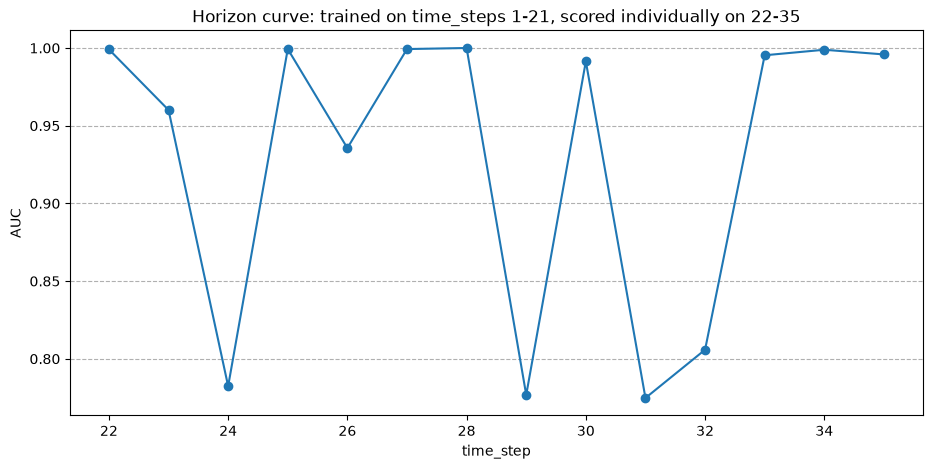

In [313]:
def evaluate_tuned_model(model, cols, name):
    model.fit(horizon_train[cols], horizon_train["label"])

    period_aucs = []
    all_true, all_pred_proba = [], []
    for t in horizon_eval_times:
        eval_rows = horizon_labeled_all[horizon_labeled_all["time_step"] == t]
        y_t = eval_rows["label"]
        if y_t.nunique() < 2:
            continue
        pred_t = model.predict_proba(eval_rows[cols])[:, 1]
        period_aucs.append((t, roc_auc_score(y_t, pred_t)))
        all_true.extend(y_t.tolist())
        all_pred_proba.extend(pred_t.tolist())

    times, aucs = zip(*period_aucs)
    aucs = np.array(aucs)

    all_true = np.array(all_true)
    all_pred_proba = np.array(all_pred_proba)
    all_pred_label = (all_pred_proba >= 0.5).astype(int)

    pooled_auc = roc_auc_score(all_true, all_pred_proba)
    f1 = f1_score(all_true, all_pred_label)
    precision = precision_score(all_true, all_pred_label, zero_division=0)
    recall = recall_score(all_true, all_pred_label, zero_division=0)

    print(f"=== {name} ===")
    print(f"Mean per-period AUC: {aucs.mean():.4f}  (std {aucs.std():.4f}, worst {aucs.min():.4f})")
    print(f"Pooled AUC (all periods together): {pooled_auc:.4f}")
    print(f"Pooled F1={f1:.4f}  Precision={precision:.4f}  Recall={recall:.4f}")
    print(classification_report(all_true, all_pred_label, target_names=["licit", "illicit"], digits=4))

    return {"mean_period_auc": aucs.mean(), "worst_period_auc": aucs.min(), "pooled_auc": pooled_auc}, dict(zip(times, aucs))


tuned_result, tuned_curve = evaluate_tuned_model(best_xgb_model, pruned_feature_cols, "XGBoost (tuned, 82 features)")

plt.figure(figsize=(11, 5))
times = sorted(tuned_curve)
plt.plot(times, [tuned_curve[t] for t in times], marker="o")
plt.xlabel("time_step")
plt.ylabel("AUC")
plt.title(f"Horizon curve: trained on time_steps 1-{HORIZON_CUTOFF}, scored individually on 22-35")
plt.grid(axis="y", linestyle="--")
plt.show()


## 7. XGBoost submission: retrain on all labeled data (1-35), predict on the real test set

Rebuilds graph features at `SUBMISSION_CUTOFF=35` (causal walk-forward for all of 1-35; one frozen model scores the real, unlabeled test set 36-49 -- the same leak-free structure validated throughout this notebook), then retrains the tuned model on every labeled row before predicting.

In [314]:
SUBMISSION_CUTOFF = 35
submission_graph_df = build_features_for_cutoff(SUBMISSION_CUTOFF)

train_full_aug = labeled.merge(submission_graph_df, on="txId", how="left")
test_aug = test.merge(submission_graph_df, on="txId", how="left")

print("Training rows (all labeled, 1-35):", len(train_full_aug))
print("Test rows (36-49):", len(test_aug))

final_xgb_model = xgb.XGBClassifier(**best_xgb_params, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1)
final_xgb_model.fit(train_full_aug[pruned_feature_cols], train_full_aug["label"])

test_pred = final_xgb_model.predict_proba(test_aug[pruned_feature_cols])[:, 1]

submission = pd.DataFrame({
    "index": test["index"],
    "target": test_pred,
})

sample_submission = pd.read_csv("data/sample_submission.csv")
assert len(submission) == len(sample_submission), "row count mismatch vs sample_submission.csv"
assert set(submission["index"]) == set(sample_submission["index"]), "index mismatch vs sample_submission.csv"

variant_parts = [
    name for name, on in [
        ("component_size", USE_COMPONENT_SIZE),
        ("nb_features_pruned" if NB_PRUNE else "nb_features_all", USE_NB_FEATURES),
    ] if on
]
submission_path = "_".join(variant_parts) + "_tuned_submission.csv" if variant_parts else "pruned_xgboost_narrow_submission.csv"
submission.to_csv(submission_path, index=False)

print(f"Saved {len(submission)} predictions to {submission_path}")
display(submission.head())

Training rows (all labeled, 1-35): 31235
Test rows (36-49): 15329
Saved 15329 predictions to pruned_xgboost_narrow_submission.csv


,index,target
0,0,0.004848
1,1,0.014198
2,2,0.008518
3,3,0.005000
4,4,0.001964


## 8. Second model: `graph_structure_v2` (82 features + 4 structural features)

Reproduces `03j_graph_structure_v2.ipynb` (public leaderboard **0.95637**), the second model in the final blend. It adds four static, label-free features to the 82-feature set above:

- **`reciprocity`** -- fraction of a node's neighbors linked in both directions. It is 0 for every node in this graph (no mutual edges), so the model ignores it; it's kept only so the feature set matches `03j` exactly.
- **`component_density`**, **`component_diameter`** -- edge density and (approximate) diameter of the node's connected component. Each time step is a single connected component (edges never cross periods), so these are constant within a period.
- **`louvain_community_size`** -- size of the node's Louvain community (312 communities vs. 49 components), so unlike the two above it does vary within a period.

The model uses the same fixed hyperparameters `03j` used (`04`'s original tuned values, hardcoded rather than taken from this run's Optuna study), so this cell reproduces the submitted file exactly.

In [315]:
G_directed = nx.from_pandas_edgelist(edges, source="txId1", target="txId2", create_using=nx.DiGraph)
G_undirected_v2 = G_directed.to_undirected()  # built from the DiGraph as in 03j: node order affects Louvain

# Reciprocity: fraction of a node's distinct neighbors that are mutual
reciprocity_rows = []
for node in G_directed.nodes():
    successors = set(G_directed.successors(node))
    predecessors = set(G_directed.predecessors(node))
    total_distinct = successors | predecessors
    rec = len(successors & predecessors) / len(total_distinct) if total_distinct else 0.0
    reciprocity_rows.append((node, rec))
reciprocity_df = pd.DataFrame(reciprocity_rows, columns=["txId", "reciprocity"])

# Component density and diameter
component_rows = []
for component in nx.connected_components(G_undirected_v2):
    sub = G_undirected_v2.subgraph(component)
    n_nodes, n_edges = sub.number_of_nodes(), sub.number_of_edges()
    density = (2 * n_edges) / (n_nodes * (n_nodes - 1)) if n_nodes > 1 else 0.0
    diameter = nx.approximation.diameter(sub, seed=RANDOM_STATE) if n_nodes > 1 else 0
    for node in component:
        component_rows.append((node, density, diameter))
component_struct_df = pd.DataFrame(component_rows, columns=["txId", "component_density", "component_diameter"])

# Louvain community size
t0 = time.time()
louvain_communities = nx.algorithms.community.louvain_communities(G_undirected_v2, seed=RANDOM_STATE)
louvain_df = pd.DataFrame(
    [(node, len(community)) for community in louvain_communities for node in community],
    columns=["txId", "louvain_community_size"],
)
print(f"Louvain: {len(louvain_communities)} communities in {time.time() - t0:.1f}s")

gsv2_static_df = (
    reciprocity_df.merge(component_struct_df, on="txId", how="left").merge(louvain_df, on="txId", how="left")
)
display(gsv2_static_df.describe())

Louvain: 312 communities in 31.7s


,txId,reciprocity,component_density,component_diameter,louvain_community_size
count,2.037690e+05,203769.0,203769.000000,203769.000000,203769.000000
mean,1.711310e+08,0.0,0.000543,117.795568,3381.698742
std,1.104655e+08,0.0,0.000212,128.690919,1781.221617
min,1.076000e+03,0.0,0.000295,41.000000,16.000000
25%,8.433452e+07,0.0,0.000404,63.000000,2209.000000
50%,1.624375e+08,0.0,0.000486,93.000000,3546.000000
75%,2.454798e+08,0.0,0.000625,129.000000,4612.000000
max,4.032446e+08,0.0,0.001972,786.000000,6677.000000


In [316]:
GSV2_NEW_COLS = ["reciprocity", "component_density", "component_diameter", "louvain_community_size"]
gsv2_feature_cols = [c for c in pruned_feature_cols if c not in OPTIONAL_GRAPH_COLS] + GSV2_NEW_COLS
assert len(gsv2_feature_cols) == 86

# 04's original tuned values, exactly as 03j used them.
GSV2_XGB_PARAMS = {
    "n_estimators": 492,
    "max_depth": 7,
    "learning_rate": 0.013888331361684582,
    "subsample": 0.7905148508506226,
    "colsample_bytree": 0.6540326354669648,
    "gamma": 0.051262131742389194,
    "reg_alpha": 1.5660599892028226,
    "reg_lambda": 2.677764464567206,
    "scale_pos_weight": 9.438268305718866,
}

# Same cutoff-35 graph features as the 04 submission above, plus the static structural features.
gsv2_train = train_full_aug.merge(gsv2_static_df, on="txId", how="left")
gsv2_test = test_aug.merge(gsv2_static_df, on="txId", how="left")

gsv2_model = xgb.XGBClassifier(**GSV2_XGB_PARAMS, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1)
gsv2_model.fit(gsv2_train[gsv2_feature_cols], gsv2_train["label"])
gsv2_pred = gsv2_model.predict_proba(gsv2_test[gsv2_feature_cols])[:, 1]

gsv2_submission = pd.DataFrame({"index": test["index"], "target": gsv2_pred})
assert len(gsv2_submission) == len(sample_submission), "row count mismatch vs sample_submission.csv"
assert set(gsv2_submission["index"]) == set(sample_submission["index"]), "index mismatch vs sample_submission.csv"

gsv2_submission_path = "graph_structure_v2_submission.csv"
gsv2_submission.to_csv(gsv2_submission_path, index=False)
print(f"Saved {len(gsv2_submission)} predictions to {gsv2_submission_path}")
display(gsv2_submission.head())

Saved 15329 predictions to graph_structure_v2_submission.csv


,index,target
0,0,0.004473
1,1,0.010434
2,2,0.006974
3,3,0.003223
4,4,0.001828


## 9. Rank blend: `04` + `graph_structure_v2`

AUC only depends on the order of predictions, and the two models' probabilities aren't on the same scale, so each model's test predictions are converted to percentile ranks and averaged 50/50 (no tuned weights). Public leaderboard: **0.95706**, effectively tied with `04` alone (0.95730) and above `graph_structure_v2` alone (0.95637).

The `target` column holds averaged ranks in [0, 1], not probabilities.

In [317]:
if USE_COMPONENT_SIZE or USE_NB_FEATURES:
    print("Skipped: the 0.95706 blend uses the original 82-feature 04 model. "
          "Set USE_COMPONENT_SIZE = False and USE_NB_FEATURES = False to rebuild it.")
else:
    blend_pred = (pd.Series(test_pred).rank(pct=True) + pd.Series(gsv2_pred).rank(pct=True)) / 2

    blend_submission = pd.DataFrame({"index": test["index"], "target": blend_pred.values})
    assert len(blend_submission) == len(sample_submission), "row count mismatch vs sample_submission.csv"
    assert set(blend_submission["index"]) == set(sample_submission["index"]), "index mismatch vs sample_submission.csv"

    blend_submission_path = "blend_rank_04_gsv2_submission.csv"
    blend_submission.to_csv(blend_submission_path, index=False)
    print(f"Spearman(04, graph_structure_v2) = {pd.Series(test_pred).corr(pd.Series(gsv2_pred), method='spearman'):.4f}")
    print(f"Saved {len(blend_submission)} predictions to {blend_submission_path}")
    display(blend_submission.head())

Spearman(04, graph_structure_v2) = 0.9915
Saved 15329 predictions to blend_rank_04_gsv2_submission.csv


,index,target
0,0,0.434503
1,1,0.645867
2,2,0.552808
3,3,0.393763
4,4,0.205786


## 10. XGBoost + MLP rank blend (public 0.95830)

It blends
the `04` XGBoost model above (locked 82 features, `04`'s tuned values) with a neural net that ranks transactions differently
(Spearman 0.80 with XGBoost on the test set), 3 parts XGBoost to 1 part MLP by rank.

| piece | what it does |
|---|---|
| quantile scaling | every input mapped to a normal distribution by rank (fitted on feature values only, no labels), which tames the heavy tails |
| periodic embeddings (Gorishniy et al. 2022) | each feature expanded into sin/cos at 8 learned frequencies, then a small linear layer per feature |
| 256 -> 128 MLP, dropout 0.3 | the network body |
| weight averaging (SWA) | weights of the last 5 epochs averaged |
| 5 seeds | predictions rank-averaged across seeds |

The MLP gets the same 82 features as XGBoost. A missing value becomes 0 after quantile scaling (the median), and a 0/1 missing
flag is added only for columns that are missing in the **training rows**. The neighbour-risk aggregates are missing for about
25% of test rows (no neighbour in the data) but never for labelled rows, so they get no flag: a flag that is always 0 in training
can't be learned. Fixing exactly this raised the public score from 0.95775 to 0.95830.

The MLP's epoch count comes from early stopping on an inner time split (1-17 -> 18-21 for the horizon check, 1-31 -> 32-35 for
the final run), so periods 22-35 never influence training. Both halves use fixed settings rather than this run's Optuna result,
so this section reproduces the submitted file exactly.

### Choosing the blend weight

All five weights blend the same two models (XGBoost : MLP = w : 1, by rank), so trying them costs no extra training.

| XGBoost : MLP | Mean AUC (22-35) | Worst period | Pooled AUC | Pooled vs XGBoost | Public LB |
|---|---|---|---|---|---|
| XGBoost alone | 0.9296 | 0.7748 | 0.9102 | -- | 0.95730 |
| 5:1 | 0.9321 | 0.7827 | 0.9144 | +0.0041 | 0.95817 |
| 4:1 | 0.9326 | 0.7846 | 0.9151 | +0.0049 | not submitted |
| **3:1** | **0.9334** | **0.7880** | **0.9162** | **+0.0060** | **0.95830** |
| 2:1 | 0.9344 | 0.7923 | 0.9179 | +0.0077 | 0.95821 |
| 1:1 | 0.9357 | 0.7970 | 0.9203 | +0.0101 | not submitted |
| MLP alone | 0.9362 | 0.7985 | 0.9212 | +0.0110 | not submitted |

**Why 3:1.** Adding the MLP at any weight beats XGBoost alone, both on 22-35 and on the leaderboard (+0.0009 to +0.0010).
Beyond that, the public scores for 5:1, 3:1 and 2:1 are within 0.00013 of each other: the leaderboard scores only about 4,600
rows, so it can't separate them. 3:1 has the highest public score, and it keeps XGBoost (the model proven on the leaderboard) as
the main model while still adding the MLP's different view. Periods 22-35 favour more MLP weight, but internal gains on this
project have repeatedly failed to carry over to the leaderboard, so that alone wasn't enough reason to move to 2:1 or 1:1.

### Other MLP experiments (separate notebooks, not rerun here)

| Experiment | Notebook | Blend 3:1, pooled AUC 22-35 | Public LB |
|---|---|---|---|
| MLP with untrained missing flags (the bug fixed above) | `06_mlp_blend.ipynb` (first run) | 0.9162 (horizon run had no flags) | 0.95775 (2:1: 0.95751) |
| **MLP, flags fixed (this section)** | `06_mlp_blend.ipynb` | **0.9162** | **0.95830** |
| FGSM adversarial training (eps 0.03) | `06_mlp_blend_fgsm.ipynb` | 0.9180 | 0.95819 |
| 10 seeds instead of 5 | `07_mlp_variants.ipynb` | 0.9161 | 0.95809 |
| Masked neighbour-risk training + 10 seeds | `07_mlp_variants.ipynb` | 0.9145 | 0.95809 |
| Masked neighbour-risk training, 5 seeds | `07_mlp_variants.ipynb` | 0.9141 | not submitted |
| Wider MLP input (166 features) | `07_mlp_variants.ipynb` | 0.9081 | not submitted |

Fixing the missing flags was the one change that clearly moved the leaderboard (+0.00055). Every later MLP change landed within
0.0002 of 0.95830, so the simplest version was kept.

In [318]:
MLP_SEEDS = [7, 42, 314, 999, 4102]  # predictions rank-averaged across seeds
MLP_ES_CUTOFF = 17                     # horizon check: epochs picked on 1-17 -> 18-21
MLP_FINAL_ES_CUTOFF = 31               # final run: epochs picked on 1-31 -> 32-35
BLEND_WEIGHTS = [5, 4, 3, 2, 1]        # XGBoost : MLP = w : 1 -- every weight tried; 3:1 is the submission
BEST_BLEND_WEIGHT = 3

# the original 82 features and 04's tuned values, fixed so the blend reproduces the 0.95830 file
mlp_model_cols = [c for c in pruned_feature_cols if c not in OPTIONAL_GRAPH_COLS]
assert len(mlp_model_cols) == 82, len(mlp_model_cols)
LOCKED_XGB_PARAMS = {
    "n_estimators": 492,
    "max_depth": 7,
    "learning_rate": 0.013888331361684582,
    "subsample": 0.7905148508506226,
    "colsample_bytree": 0.6540326354669648,
    "gamma": 0.051262131742389194,
    "reg_alpha": 1.5660599892028226,
    "reg_lambda": 2.677764464567206,
    "scale_pos_weight": 9.438268305718866,
}


def fit_locked_xgb(X, y):
    return xgb.XGBClassifier(**LOCKED_XGB_PARAMS, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1).fit(X, y)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

class MLPHead(nn.Module):
    """Feed-forward classifier: Linear -> ReLU -> Dropout for each hidden layer, then one output logit."""

    def __init__(self, in_dim, hidden=(256, 128), p_drop=0.3):
        super().__init__()
        blocks = []
        width = in_dim
        for out_dim in hidden:
            blocks.extend([nn.Linear(width, out_dim), nn.ReLU(), nn.Dropout(p_drop)])
            width = out_dim
        blocks.append(nn.Linear(width, 1))
        self.layers = nn.Sequential(*blocks)

    def forward(self, x):
        return self.layers(x).squeeze(-1)       


class PeriodicFeatureEncoder(nn.Module):
    """Encodes each scalar feature x_j as ReLU(W_j [sin(2*pi*f_j*x_j), cos(2*pi*f_j*x_j)] + b_j),
    with n_freq learnt frequencies f_j and an out_dim-sized output per feature (Gorishniy et al., 2022)."""

    def __init__(self, n_features, n_freq=8, out_dim=8, freq_scale=0.1):
        super().__init__()
        self.freqs = nn.Parameter(torch.randn(n_features, n_freq) * freq_scale)                          # (F, K)
        self.proj = nn.Parameter(torch.randn(n_features, 2 * n_freq, out_dim) / math.sqrt(2 * n_freq))  # (F, 2K, D)
        self.bias = nn.Parameter(torch.zeros(n_features, out_dim))                                       # (F, D)

    def forward(self, x):                                                        # x: (B, F)
        angles = 2 * math.pi * self.freqs.unsqueeze(0) * x.unsqueeze(-1)         # (B, F, K)
        periodic = torch.cat([angles.sin(), angles.cos()], dim=-1)               # (B, F, 2K)
        encoded = torch.einsum("bfi,fid->bfd", periodic, self.proj) + self.bias  # (B, F, D)
        return encoded.relu().flatten(start_dim=1)  


class PeriodicMLP(nn.Module):
    """Periodic per-feature encoding followed by the MLP head."""

    def __init__(self, n_features, emb_dim=8):
        super().__init__()
        self.encoder = PeriodicFeatureEncoder(n_features, out_dim=emb_dim)
        self.head = MLPHead(n_features * emb_dim)

    def forward(self, x):
        return self.head(self.encoder(x))


def make_loader(X, y=None, batch_size=256, shuffle=False):
    xt = torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))
    if y is None:
        return DataLoader(TensorDataset(xt), batch_size=batch_size, shuffle=shuffle)
    yt = torch.from_numpy(np.asarray(y, dtype=np.float32))
    return DataLoader(TensorDataset(xt, yt), batch_size=batch_size, shuffle=shuffle)


def predict_mlp(model, X):
    model.eval()
    out = []
    with torch.no_grad():
        for (xb,) in make_loader(X, batch_size=2048):
            out.append(torch.sigmoid(model(xb.to(DEVICE))).cpu().numpy())
    return np.concatenate(out)


def epochs_by_early_stopping(X_tr, y_tr, X_va, y_va, seed, max_epochs=60, patience=5):
    set_seed(seed)
    model = PeriodicMLP(X_tr.shape[1]).to(DEVICE)
    opt, crit = optim.Adam(model.parameters(), lr=1e-3), nn.BCEWithLogitsLoss()
    loader = make_loader(X_tr, y_tr, shuffle=True)
    best_auc, best_epoch, wait = -1, 1, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            crit(model(xb.to(DEVICE)), yb.to(DEVICE)).backward()
            opt.step()
        auc = roc_auc_score(y_va, predict_mlp(model, X_va))
        if auc > best_auc:
            best_auc, best_epoch, wait = auc, epoch, 0
        else:
            wait += 1
        if wait >= patience:
            break
    return best_epoch


def train_swa(X, y, n_epochs, seed, swa_last=5):
    set_seed(seed)
    model = PeriodicMLP(X.shape[1]).to(DEVICE)
    opt, crit = optim.Adam(model.parameters(), lr=1e-3), nn.BCEWithLogitsLoss()
    swa = torch.optim.swa_utils.AveragedModel(model)
    loader = make_loader(X, y, shuffle=True)
    for epoch in range(1, n_epochs + 1):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            crit(model(xb.to(DEVICE)), yb.to(DEVICE)).backward()
            opt.step()
        if epoch > n_epochs - swa_last:
            swa.update_parameters(model)
    return swa


def mlp_inputs(fit_df, frames, cols, train_frame):
    # quantile scaling fitted on feature values only (no labels); NaN -> 0, plus a missing flag only for
    # columns that are missing in the training rows (a flag that's always 0 in training can't be learned)
    nan_cols = [c for c in cols if train_frame[c].isna().any()]
    qt = QuantileTransformer(n_quantiles=min(1000, len(fit_df)), output_distribution="normal", random_state=RANDOM_STATE)
    qt.fit(fit_df[cols].values)
    out = []
    for f in frames:
        x = np.nan_to_num(qt.transform(f[cols].values), nan=0.0)
        flags = f[nan_cols].isna().values.astype(np.float32)
        out.append(np.hstack([x, flags]).astype(np.float32))
    return out, nan_cols


def run_mlp(X_es_tr, y_es_tr, X_es_va, y_es_va, X_fit, y_fit, X_score, seeds=MLP_SEEDS):
    # per seed: epoch count from the inner split, then an SWA model on the full window; predictions rank-averaged over seeds
    preds, epochs = [], []
    for s in seeds:
        ep = epochs_by_early_stopping(X_es_tr, y_es_tr, X_es_va, y_es_va, seed=s)
        n_ep = max(ep, 5) + 2
        preds.append(pd.Series(predict_mlp(train_swa(X_fit, y_fit, n_ep, seed=s), X_score)).rank(pct=True).values)
        epochs.append(n_ep)
    return np.mean(preds, axis=0), epochs


def rank_blend(preds, weights):
    ranks = [pd.Series(p).rank(pct=True).values for p in preds]
    return np.average(ranks, axis=0, weights=weights)

### 10.1 Horizon check: train on 1-21, score each of 22-35

Same protocol as the horizon curves above. Both models are trained on 1-21 only.

MLP inputs: 82 (82 features + 0 missing flags)
MLP done in 88s | epochs per seed [10, 13, 8, 19, 18]
Spearman XGBoost vs MLP on 22-35: 0.8609


,mean_period_auc,worst_period_auc,pooled_auc,pooled_vs_xgb
model,,,,
xgb (0.95730 setup),0.9296,0.7748,0.9102,0.0000
blend xgb:mlp 5:1,0.9320,0.7819,0.9143,0.0041
blend xgb:mlp 4:1,0.9325,0.7835,0.9151,0.0049
blend xgb:mlp 3:1,0.9332,0.7864,0.9162,0.0060
blend xgb:mlp 2:1,0.9341,0.7900,0.9178,0.0076
blend xgb:mlp 1:1,0.9354,0.7956,0.9201,0.0099
mlp,0.9359,0.7980,0.9214,0.0112


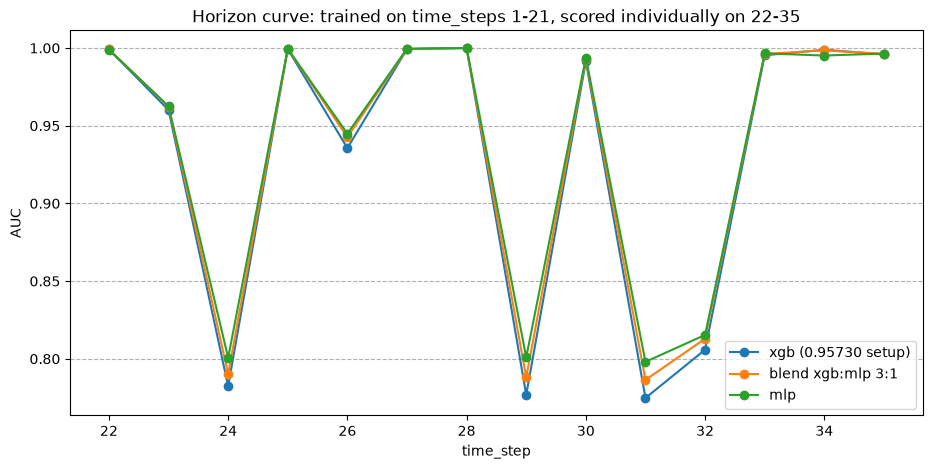

In [319]:
t0 = time.time()
h_all = labeled.merge(horizon_graph_df, on="txId", how="left")  # cutoff-21 graph features, built for the pruning analysis
h_train = h_all[h_all["time_step"] <= HORIZON_CUTOFF].reset_index(drop=True)
h_eval = h_all[h_all["time_step"] > HORIZON_CUTOFF].reset_index(drop=True)

p_xgb_h = fit_locked_xgb(h_train[mlp_model_cols], h_train["label"]).predict_proba(h_eval[mlp_model_cols])[:, 1]

es_tr = h_train[h_train["time_step"] <= MLP_ES_CUTOFF]
es_va = h_train[h_train["time_step"] > MLP_ES_CUTOFF]
(X_es_tr, X_es_va, X_h_tr, X_h_ev), h_nan_cols = mlp_inputs(
    h_all, [es_tr, es_va, h_train, h_eval], mlp_model_cols, train_frame=h_train)
print("MLP inputs:", X_h_tr.shape[1], f"({len(mlp_model_cols)} features + {len(h_nan_cols)} missing flags)")

p_mlp_h, h_epochs = run_mlp(X_es_tr, es_tr["label"].values, X_es_va, es_va["label"].values,
                            X_h_tr, h_train["label"].values, X_h_ev)
print(f"MLP done in {time.time() - t0:.0f}s | epochs per seed {h_epochs}")
print("Spearman XGBoost vs MLP on 22-35: {:.4f}".format(pd.Series(p_xgb_h).corr(pd.Series(p_mlp_h), method="spearman")))


def blend_horizon_summary(pred, name):
    per = {}
    for t in sorted(h_eval["time_step"].unique()):
        m = (h_eval["time_step"] == t).values
        y = h_eval.loc[m, "label"]
        if y.nunique() == 2:
            per[t] = roc_auc_score(y, pred[m])
    per = pd.Series(per)
    return {"model": name, "mean_period_auc": per.mean(), "worst_period_auc": per.min(),
            "pooled_auc": roc_auc_score(h_eval["label"], pred)}, per


blend_candidates = {"xgb (0.95730 setup)": p_xgb_h}
for w in BLEND_WEIGHTS:
    blend_candidates[f"blend xgb:mlp {w}:1"] = rank_blend([p_xgb_h, p_mlp_h], [w, 1])
blend_candidates["mlp"] = p_mlp_h
blend_rows, blend_curves = [], {}
for name, pred in blend_candidates.items():
    row, per = blend_horizon_summary(pred, name)
    blend_rows.append(row)
    blend_curves[name] = per
blend_horizon_df = pd.DataFrame(blend_rows).set_index("model")
blend_horizon_df["pooled_vs_xgb"] = blend_horizon_df["pooled_auc"] - blend_horizon_df.loc["xgb (0.95730 setup)", "pooled_auc"]
display(blend_horizon_df.round(4))

plt.figure(figsize=(11, 5))
for name in ["xgb (0.95730 setup)", f"blend xgb:mlp {BEST_BLEND_WEIGHT}:1", "mlp"]:
    per = blend_curves[name]
    plt.plot(per.index, per.values, marker="o", label=name)
plt.xlabel("time_step")
plt.ylabel("AUC")
plt.title(f"Horizon curve: trained on time_steps 1-{HORIZON_CUTOFF}, scored individually on 22-35")
plt.grid(axis="y", linestyle="--")
plt.legend()
plt.show()

### 10.2 Final run: train on 1-35, score the test set (36-49)

XGBoost is refit on all labelled rows with the locked settings. The MLP picks its epochs on 1-31 -> 32-35, then trains on 1-35.
The quantile scaler is fitted on the feature values of the labelled rows plus the test rows (no labels involved).

In [320]:
# Same cutoff-35 graph features as the XGBoost submission in section 7 (train_full_aug / test_aug)
assert (test_aug["index"].values == test["index"].values).all()
p_xgb_final = fit_locked_xgb(train_full_aug[mlp_model_cols], train_full_aug["label"]).predict_proba(test_aug[mlp_model_cols])[:, 1]

f_es_tr = train_full_aug[train_full_aug["time_step"] <= MLP_FINAL_ES_CUTOFF]
f_es_va = train_full_aug[train_full_aug["time_step"] > MLP_FINAL_ES_CUTOFF]
fit_pool = pd.concat([train_full_aug[mlp_model_cols], test_aug[mlp_model_cols]], ignore_index=True)
(X_f_es_tr, X_f_es_va, X_f_all, X_f_te), f_nan_cols = mlp_inputs(
    fit_pool, [f_es_tr, f_es_va, train_full_aug, test_aug], mlp_model_cols, train_frame=train_full_aug)
assert f_nan_cols == h_nan_cols, (f_nan_cols, h_nan_cols)  # same inputs as in the horizon check
print("Final MLP inputs:", X_f_all.shape[1], f"({len(mlp_model_cols)} features + {len(f_nan_cols)} missing flags)")

t0 = time.time()
p_mlp_final, f_epochs = run_mlp(X_f_es_tr, f_es_tr["label"].values, X_f_es_va, f_es_va["label"].values,
                                X_f_all, train_full_aug["label"].values, X_f_te)
print(f"MLP done in {time.time() - t0:.0f}s | epochs per seed {f_epochs}")
print("Spearman XGBoost vs MLP on test: {:.4f}".format(pd.Series(p_xgb_final).corr(pd.Series(p_mlp_final), method="spearman")))

blend_preds = {w: rank_blend([p_xgb_final, p_mlp_final], [w, 1]) for w in BLEND_WEIGHTS}
for w, pred in blend_preds.items():
    sub = pd.DataFrame({"index": test["index"].values, "target": pred})
    assert len(sub) == len(sample_submission), "row count mismatch vs sample_submission.csv"
    assert set(sub["index"]) == set(sample_submission["index"]), "index mismatch vs sample_submission.csv"
    path = f"xgb_mlp_blend_{w}to1_submission.csv"
    sub.to_csv(path, index=False)
    print(f"Saved {len(sub)} predictions to {path}" + ("  <- public 0.95830; section 11 builds the final submission on this blend" if w == BEST_BLEND_WEIGHT else ""))

xgb_mlp_pred = blend_preds[BEST_BLEND_WEIGHT]
display(pd.DataFrame({"index": test["index"].values, "target": xgb_mlp_pred}).head())

Final MLP inputs: 82 (82 features + 0 missing flags)
MLP done in 103s | epochs per seed [12, 12, 12, 10, 7]
Spearman XGBoost vs MLP on test: 0.8170
Saved 15329 predictions to xgb_mlp_blend_5to1_submission.csv
Saved 15329 predictions to xgb_mlp_blend_4to1_submission.csv
Saved 15329 predictions to xgb_mlp_blend_3to1_submission.csv  <- public 0.95830; section 11 builds the final submission on this blend
Saved 15329 predictions to xgb_mlp_blend_2to1_submission.csv
Saved 15329 predictions to xgb_mlp_blend_1to1_submission.csv


,index,target
0,0,0.444745
1,1,0.664623
2,2,0.563442
3,3,0.426708
4,4,0.186933


## 11. Final submission: time-decay weights for the MLP (public 0.95876), and the drift experiments around it

Reproduces notebooks `11_drift_ideas`, `12_decay_sweep` and `13_mlp_decay_ensemble`, which tried three ways of coping with the
drift between training and test periods. The final submission is **XGBoost (no decay) + an MLP trained with time-decay weights
0.98, rank-blended 3:1**: public **0.95876**, the highest score of the project.

| idea | what changes | variants |
|---|---|---|
| **Time-decay weights** | each training row weighted by λ^(cutoff - time step), so recent periods count more | XGBoost: λ = 0.8, 0.9, 0.95, 0.97, 0.98, 0.99. MLP: λ = 0.95, 0.97, 0.98, 0.99, and the average of the 0.97/0.98/0.99 MLPs |
| **Within-period ranks** | each raw feature replaced by its percentile rank among transactions of the same time step (XGBoost) | one |
| **Graph smoothing** | final score mixed with its neighbours' scores: (1 - α) x own rank + α x neighbours' mean rank | α = 0.2, 0.4 |

The plain XGBoost and MLP predictions come from section 10; only the new models are trained here. Every blend is a rank blend
with the stated XGBoost : MLP weight.

**Public leaderboard results** (every file submitted from these experiments):

| file | XGBoost | MLP | weight | public LB |
|---|---|---|---|---|
| `base_blend_xgb_mlp_3to1` (section 10) | no decay | no decay | 3:1 | 0.95830 |
| `xgbdecay095_blend_xgb_mlp_3to1` | decay 0.95 | no decay | 3:1 | 0.95842 |
| `bothdecay098_blend_xgb_mlp_3to1` | decay 0.98 | decay 0.98 | 3:1 | 0.95817 |
| **`xgbnone_mlpdecay098_blend_3to1` (final)** | **no decay** | **decay 0.98** | **3:1** | **0.95876** |
| `mlpdecayens_blend_xgb_mlp_3to1` | no decay | average of 0.97/0.98/0.99 | 3:1 | 0.95875 |
| `mlpdecayens_blend_xgb_mlp_1to1` | no decay | average of 0.97/0.98/0.99 | 1:1 | 0.95847 |
| `smooth020_blend_xgb_mlp_3to1` | no decay | no decay, smoothed α = 0.2 | 3:1 | 0.94753 |

The other variants were not submitted: they scored clearly worse on periods 22-35 (strong decay, ranks, more smoothing), or
ranked test rows almost exactly like a file already submitted (Spearman 0.995 or more), so they would have scored the same.

In [321]:
XGB_DECAY_LAMBDAS = [0.8, 0.9, 0.95, 0.97, 0.98, 0.99]
MLP_DECAY_LAMBDAS = [0.95, 0.97, 0.98, 0.99]
MLP_ENSEMBLE_LAMBDAS = [0.97, 0.98, 0.99]
SMOOTH_ALPHAS = [0.2, 0.4]
FINAL_SUBMISSION = "xgbnone_mlpdecay098_blend_3to1"


# --- time-decay weights ---
def decay_weights(time_steps, cutoff, lam):
    # weight 1 for the latest training period, lam for the one before, lam**2 before that, ...
    return lam ** (cutoff - np.asarray(time_steps, dtype=float))


def fit_locked_xgb_weighted(X, y, w):
    return xgb.XGBClassifier(**LOCKED_XGB_PARAMS, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1).fit(X, y, sample_weight=w)


def make_weighted_loader(X, y, w, batch_size=256):
    to_t = lambda a: torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32))
    return DataLoader(TensorDataset(to_t(X), to_t(y), to_t(w)), batch_size=batch_size, shuffle=True)


def weighted_step(model, opt, crit, xb, yb, wb):
    # each row's loss times its weight, normalised by the batch's total weight
    opt.zero_grad()
    loss = (crit(model(xb.to(DEVICE)), yb.to(DEVICE)) * wb.to(DEVICE)).sum() / wb.sum().to(DEVICE)
    loss.backward()
    opt.step()


def epochs_by_early_stopping_w(X_tr, y_tr, w_tr, X_va, y_va, seed, max_epochs=60, patience=5):
    set_seed(seed)
    model = PeriodicMLP(X_tr.shape[1]).to(DEVICE)
    opt, crit = optim.Adam(model.parameters(), lr=1e-3), nn.BCEWithLogitsLoss(reduction="none")
    loader = make_weighted_loader(X_tr, y_tr, w_tr)
    best_auc, best_epoch, wait = -1, 1, 0
    for epoch in range(1, max_epochs + 1):
        model.train()
        for xb, yb, wb in loader:
            weighted_step(model, opt, crit, xb, yb, wb)
        auc = roc_auc_score(y_va, predict_mlp(model, X_va))  # the validation split stays unweighted
        if auc > best_auc:
            best_auc, best_epoch, wait = auc, epoch, 0
        else:
            wait += 1
        if wait >= patience:
            break
    return best_epoch


def train_swa_w(X, y, w, n_epochs, seed, swa_last=5):
    set_seed(seed)
    model = PeriodicMLP(X.shape[1]).to(DEVICE)
    opt, crit = optim.Adam(model.parameters(), lr=1e-3), nn.BCEWithLogitsLoss(reduction="none")
    swa = torch.optim.swa_utils.AveragedModel(model)
    loader = make_weighted_loader(X, y, w)
    for epoch in range(1, n_epochs + 1):
        model.train()
        for xb, yb, wb in loader:
            weighted_step(model, opt, crit, xb, yb, wb)
        if epoch > n_epochs - swa_last:
            swa.update_parameters(model)
    return swa


def run_mlp_w(X_es_tr, y_es_tr, w_es_tr, X_es_va, y_es_va, X_fit, y_fit, w_fit, X_score, seeds=MLP_SEEDS):
    # same protocol as run_mlp in section 10, with per-row weights on the training loss
    preds, epochs = [], []
    for s in seeds:
        ep = epochs_by_early_stopping_w(X_es_tr, y_es_tr, w_es_tr, X_es_va, y_es_va, seed=s)
        n_ep = max(ep, 5) + 2
        preds.append(pd.Series(predict_mlp(train_swa_w(X_fit, y_fit, w_fit, n_ep, seed=s), X_score)).rank(pct=True).values)
        epochs.append(n_ep)
    return np.mean(preds, axis=0), epochs


def mlp_ensemble(p_by_lambda, lambdas):
    return np.mean([pd.Series(p_by_lambda[lam]).rank(pct=True).values for lam in lambdas], axis=0)


# --- ranks within each time step (feature values only, no labels) ---
RAW_MODEL_COLS = [c for c in mlp_model_cols if c.startswith("feat_")]
rank_pool = pd.concat([labeled[["txId", "time_step"] + RAW_MODEL_COLS], test[["txId", "time_step"] + RAW_MODEL_COLS]],
                      ignore_index=True)  # labelled rows + test rows (test.csv holds only labelled transactions)
ranked_raw = rank_pool.groupby("time_step")[RAW_MODEL_COLS].rank(pct=True)
ranked_raw.insert(0, "txId", rank_pool["txId"].values)


def with_ranked_raw(df):
    out = df.drop(columns=RAW_MODEL_COLS).merge(ranked_raw, on="txId", how="left")
    assert len(out) == len(df) and (out["txId"].values == df["txId"].values).all()
    return out


# --- graph smoothing of the final scores ---
undirected_edges = pd.concat([
    edges.rename(columns={"txId1": "node", "txId2": "neighbor"}),
    edges.rename(columns={"txId2": "node", "txId1": "neighbor"}),
], ignore_index=True)


def smooth_scores(txids, scores, alpha):
    # neighbours = other rows in the scored set only (as in test.csv); rows with none keep their own rank
    own = pd.Series(pd.Series(scores).rank(pct=True).values, index=txids)
    e = undirected_edges[undirected_edges["node"].isin(own.index) & undirected_edges["neighbor"].isin(own.index)]
    nb_mean = e.assign(score=e["neighbor"].map(own)).groupby("node")["score"].mean()
    nb = pd.Series(txids).map(nb_mean).values
    return np.where(np.isnan(nb), own.values, (1 - alpha) * own.values + alpha * nb)


def tag(x):
    return f"{int(round(x * 100)):03d}"


def make_decay_candidates(p_xgb, p_xgb_decay, p_xgb_rank, p_mlp, p_mlp_decay, txids):
    # every variant tried in notebooks 11-13; key = file name
    c = {"base_blend_xgb_mlp_3to1": rank_blend([p_xgb, p_mlp], [3, 1])}
    for lam, p in p_xgb_decay.items():
        c[f"xgbdecay{tag(lam)}_blend_xgb_mlp_3to1"] = rank_blend([p, p_mlp], [3, 1])
    c["rank_blend_xgb_mlp_3to1"] = rank_blend([p_xgb_rank, p_mlp], [3, 1])
    for a in SMOOTH_ALPHAS:
        c[f"smooth{tag(a)}_blend_xgb_mlp_3to1"] = smooth_scores(txids, c["base_blend_xgb_mlp_3to1"], a)
    for lam in (0.95, 0.98):
        c[f"bothdecay{tag(lam)}_blend_xgb_mlp_3to1"] = rank_blend([p_xgb_decay[lam], p_mlp_decay[lam]], [3, 1])
    for lam, p in p_mlp_decay.items():
        c[f"xgbnone_mlpdecay{tag(lam)}_blend_3to1"] = rank_blend([p_xgb, p], [3, 1])
    c["xgbnone_mlpdecay098_blend_2to1"] = rank_blend([p_xgb, p_mlp_decay[0.98]], [2, 1])
    for w in (3, 2):
        c[f"xgbdecay095_mlpdecay098_blend_{w}to1"] = rank_blend([p_xgb_decay[0.95], p_mlp_decay[0.98]], [w, 1])
    ens = mlp_ensemble(p_mlp_decay, MLP_ENSEMBLE_LAMBDAS)
    for w in (3, 2, 1):
        c[f"mlpdecayens_blend_xgb_mlp_{w}to1"] = rank_blend([p_xgb, ens], [w, 1])
    return c


print(f"Ranked {len(RAW_MODEL_COLS)} raw features within each time step | final submission: {FINAL_SUBMISSION}")

Ranked 75 raw features within each time step | final submission: xgbnone_mlpdecay098_blend_3to1


### 11.1 Horizon check: train on 1-21, score each of 22-35

Same protocol and rows as section 10.1; the plain XGBoost (`p_xgb_h`) and MLP (`p_mlp_h`) come from there. Decay weights are
relative to time step 21 (17 for the MLP's early-stopping run); the validation split that picks the MLP's epoch count stays
unweighted.

In [322]:
t0 = time.time()
p_xgb_decay_h = {
    lam: fit_locked_xgb_weighted(h_train[mlp_model_cols], h_train["label"], decay_weights(h_train["time_step"], HORIZON_CUTOFF, lam))
    .predict_proba(h_eval[mlp_model_cols])[:, 1]
    for lam in XGB_DECAY_LAMBDAS
}
h_train_r, h_eval_r = with_ranked_raw(h_train), with_ranked_raw(h_eval)
p_xgb_rank_h = fit_locked_xgb(h_train_r[mlp_model_cols], h_train_r["label"]).predict_proba(h_eval_r[mlp_model_cols])[:, 1]
print(f"XGBoost variants done in {time.time() - t0:.0f}s")

p_mlp_decay_h = {}
for lam in MLP_DECAY_LAMBDAS:
    t0 = time.time()
    p_mlp_decay_h[lam], _ = run_mlp_w(
        X_es_tr, es_tr["label"].values, decay_weights(es_tr["time_step"], MLP_ES_CUTOFF, lam), X_es_va, es_va["label"].values,
        X_h_tr, h_train["label"].values, decay_weights(h_train["time_step"], HORIZON_CUTOFF, lam), X_h_ev)
    print(f"MLP (decay {lam}) done in {time.time() - t0:.0f}s")

sp = lambda a, b: pd.Series(a).corr(pd.Series(b), method="spearman")
single_models = {"xgb (no decay)": p_xgb_h, **{f"xgb decay {lam}": p for lam, p in p_xgb_decay_h.items()},
                 "xgb within-period ranks": p_xgb_rank_h, "mlp (no decay)": p_mlp_h,
                 **{f"mlp decay {lam}": p for lam, p in p_mlp_decay_h.items()},
                 "mlp decay ensemble (0.97/0.98/0.99)": mlp_ensemble(p_mlp_decay_h, MLP_ENSEMBLE_LAMBDAS)}
decay_candidates_h = make_decay_candidates(p_xgb_h, p_xgb_decay_h, p_xgb_rank_h, p_mlp_h, p_mlp_decay_h, h_eval["txId"].values)

decay_rows = []
for name, pred in {**single_models, **decay_candidates_h}.items():
    row, _ = blend_horizon_summary(pred, name)
    decay_rows.append(row)
decay_horizon_df = pd.DataFrame(decay_rows).set_index("model")
base_row = decay_horizon_df.loc["base_blend_xgb_mlp_3to1"]
decay_horizon_df["mean_vs_base_blend"] = decay_horizon_df["mean_period_auc"] - base_row["mean_period_auc"]
decay_horizon_df["pooled_vs_base_blend"] = decay_horizon_df["pooled_auc"] - base_row["pooled_auc"]
display(decay_horizon_df.round(4))

XGBoost variants done in 21s
MLP (decay 0.95) done in 95s
MLP (decay 0.97) done in 106s
MLP (decay 0.98) done in 99s
MLP (decay 0.99) done in 95s


,mean_period_auc,worst_period_auc,pooled_auc,mean_vs_base_blend,pooled_vs_base_blend
model,,,,,
xgb (no decay),0.9296,0.7748,0.9102,-0.0035,-0.0060
xgb decay 0.8,0.8826,0.5837,0.8206,-0.0506,-0.0956
xgb decay 0.9,0.9175,0.7247,0.8883,-0.0157,-0.0279
xgb decay 0.95,0.9293,0.7682,0.9088,-0.0039,-0.0074
xgb decay 0.97,0.9293,0.7713,0.9100,-0.0039,-0.0062
xgb decay 0.98,0.9274,0.7661,0.9048,-0.0058,-0.0114
xgb decay 0.99,0.9292,0.7708,0.9094,-0.0040,-0.0068
xgb within-period ranks,0.8859,0.5907,0.8163,-0.0473,-0.0998
mlp (no decay),0.9359,0.7980,0.9214,0.0027,0.0052


### 11.2 Final run: train on 1-35, score the test set (36-49)

Plain XGBoost and MLP predictions come from section 10.2; decay weights are relative to time step 35 (31 for the MLP's
early-stopping run). Every variant's file is written with the prefix `decay_`; the final submission is also written as
`final_submission.csv`.

In [323]:
t0 = time.time()
p_xgb_decay_final = {
    lam: fit_locked_xgb_weighted(train_full_aug[mlp_model_cols], train_full_aug["label"],
                                 decay_weights(train_full_aug["time_step"], SUBMISSION_CUTOFF, lam))
    .predict_proba(test_aug[mlp_model_cols])[:, 1]
    for lam in XGB_DECAY_LAMBDAS
}
train_full_r, test_aug_r = with_ranked_raw(train_full_aug), with_ranked_raw(test_aug)
p_xgb_rank_final = fit_locked_xgb(train_full_r[mlp_model_cols], train_full_r["label"]).predict_proba(test_aug_r[mlp_model_cols])[:, 1]
print(f"XGBoost variants done in {time.time() - t0:.0f}s")

p_mlp_decay_final = {}
for lam in MLP_DECAY_LAMBDAS:
    t0 = time.time()
    p_mlp_decay_final[lam], _ = run_mlp_w(
        X_f_es_tr, f_es_tr["label"].values, decay_weights(f_es_tr["time_step"], MLP_FINAL_ES_CUTOFF, lam), X_f_es_va, f_es_va["label"].values,
        X_f_all, train_full_aug["label"].values, decay_weights(train_full_aug["time_step"], SUBMISSION_CUTOFF, lam), X_f_te)
    print(f"MLP (decay {lam}) done in {time.time() - t0:.0f}s")

decay_files = make_decay_candidates(p_xgb_final, p_xgb_decay_final, p_xgb_rank_final, p_mlp_final, p_mlp_decay_final, test["txId"].values)


def save_submission(pred, path):
    sub = pd.DataFrame({"index": test["index"].values, "target": pred})
    assert len(sub) == len(sample_submission), "row count mismatch vs sample_submission.csv"
    assert set(sub["index"]) == set(sample_submission["index"]), "index mismatch vs sample_submission.csv"
    assert np.isfinite(sub["target"]).all() and sub["target"].between(0, 1).all()
    sub.to_csv(path, index=False)


for name, pred in decay_files.items():
    save_submission(pred, f"decay_{name}_submission.csv")
save_submission(decay_files[FINAL_SUBMISSION], "final_submission.csv")
print(f"Wrote {len(decay_files)} files with prefix decay_, and final_submission.csv (= {FINAL_SUBMISSION})")

XGBoost variants done in 24s
MLP (decay 0.95) done in 111s
MLP (decay 0.97) done in 113s
MLP (decay 0.98) done in 102s
MLP (decay 0.99) done in 95s
Wrote 22 files with prefix decay_, and final_submission.csv (= xgbnone_mlpdecay098_blend_3to1)
